# Phase 8 — descriptive dataset and final-test EDA

This **self-contained local notebook** uses the frozen Dataset A manifests and saved Phase 8 predictions. It does not load a model, run inference, train, select a checkpoint, or change the CER policy. The test set has already been opened; all slices below are post-hoc descriptions.

**Where to run:** in Jupyter or VS Code on the computer holding `<BTP_ROOT>`, using the project's `.venv` Python kernel. No Kaggle GPU is needed. Run the cells from top to bottom. The notebook writes only aggregate tables, plots, a short report, and a ZIP under `reports/`; it never exports sample IDs, reference text, hypotheses, audio, or component mappings.

**Inputs:** frozen train/validation/test Parquet files, `freeze_record.json`, saved B0/F1 prediction ZIP, and the published Phase 8 aggregate JSON. The input gate verifies hashes, exact 683-clip coverage, reference agreement, and all reported totals before drawing a plot. `tqdm` is used when installed; a clear progress fallback works in the local `.venv` without it.


## 1. Environment and paths

Select the BTP `.venv` kernel. This cell imports the plotting and data libraries, finds the BTP root, declares fixed analysis bins, and creates a writable output folder. Each later cell has its own progress or status output.


In [1]:
# Import standard libraries and the local data/plotting stack.
from __future__ import annotations
import hashlib, json, os, re, unicodedata
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import numpy as np
import pandas as pd

# Put Matplotlib's font cache in a writable temporary folder before import.
os.environ.setdefault("MPLCONFIGDIR", "/private/tmp/btp_phase8_mpl_cache")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# Prefer tqdm for live progress; the existing local venv can still run without it.
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(items, *, desc: str, total: int | None = None, **_kwargs):
        count = total if total is not None else len(items)
        interval = max(1, count // 10)
        for index, item in enumerate(items, 1):
            if index == 1 or index % interval == 0 or index == count:
                print(f"{desc}: {index}/{count} ({index / count:.0%})", flush=True)
            yield item

# Locate the frozen BTP checkout from this computer or the notebook working directory.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "manifests/frozen_A_narration_phase3_5b_v1/freeze_record.json").is_file()), None)
assert ROOT is not None, "Open this notebook on the computer with the BTP frozen manifests."
FROZEN = ROOT / "manifests/frozen_A_narration_phase3_5b_v1"
PREDICTIONS = ROOT / "artifacts/exports/phase8/test_predictions.zip"
AGGREGATE = ROOT / "docs/PHASE8_RESULTS_AGGREGATE.json"
PHASE1 = ROOT / "outputs/phase1_20261031_202929/phase1_candidates.parquet"
MASTER = ROOT / "manifests/master_A_v1_1.parquet"
out = ROOT / "reports/phase8_descriptive_eda_2026-11-10"
plots, tables = out / "plots", out / "tables"
plots.mkdir(parents=True, exist_ok=True)
tables.mkdir(parents=True, exist_ok=True)
DURATION_EDGES = [0, 3, 6, 10, 20, 30]
DURATION_LABELS = ["0.5–3 s", ">3–6 s", ">6–10 s", ">10–20 s", ">20–30 s"]
LENGTH_EDGES = [0, 40, 80, 120, float("inf")]
LENGTH_LABELS = ["1–40", "41–80", "81–120", ">120"]
COLORS = {"B0": "#C45A45", "F1": "#227C91"}
print({"root": str(ROOT), "output": str(out), "gpu_needed": False})


{'root': '<BTP_ROOT>', 'output': '<BTP_ROOT>/reports/phase8_descriptive_eda_2026-11-10', 'gpu_needed': False}


## 2. Input and scoring gate

Verify the five frozen-file hashes, ZIP integrity, references, and the published 683-clip test totals. The full rows remain in memory only; subsequent exports contain aggregates.


In [2]:
def sha256(path: Path) -> str:
    """Hash one frozen file without printing any private rows."""
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def normalize(text: str) -> str:
    """Apply the declared NFD and whitespace reference policy."""
    return re.sub(r" {2,}", " ", unicodedata.normalize("NFD", text).strip())

def load_inputs() -> tuple[pd.DataFrame, pd.DataFrame, dict, dict]:
    """Validate frozen inputs and load only the two declared prediction sets."""
    freeze = json.loads((FROZEN / "freeze_record.json").read_text())
    for name, expected in tqdm(freeze["manifest_sha256"].items(), desc="Checking frozen manifests", unit="file"):
        assert sha256(FROZEN / name) == expected, f"Frozen manifest hash changed: {name}"

    needed = ["sample_id", "duration_exact", "transcript_phase2", "gender", "age_group",
              "recording_month", "domain", "component_id", "speaker_group_id"]
    splits = []
    for split in tqdm(("train", "validation", "test"), desc="Reading split metadata", unit="split"):
        frame = pd.read_parquet(FROZEN / f"{split}.parquet", columns=needed)
        assert len(frame) == freeze["splits"][split]["clips"]
        assert frame.sample_id.is_unique
        frame["split"] = split
        splits.append(frame)
    all_meta = pd.concat(splits, ignore_index=True)
    test_meta = all_meta.loc[all_meta.split.eq("test")].copy()

    expected_names = {
        "B0_test_predictions_private.jsonl": "B0",
        "F1_selected_test_predictions_private.jsonl": "F1",
    }
    predictions = []
    with ZipFile(PREDICTIONS) as archive:
        assert archive.testzip() is None, "Prediction ZIP failed integrity check"
        assert set(archive.namelist()) == set(expected_names), "Unexpected prediction archive members"
        for name, model in tqdm(expected_names.items(), desc="Reading saved predictions", unit="model"):
            rows = [json.loads(line) for line in archive.read(name).decode("utf-8").splitlines() if line]
            assert len(rows) == 683
            minimal = []
            for row in tqdm(rows, desc=f"Validating {model} rows", unit="clip"):
                assert normalize(row["reference"]) == row["reference"] and row["reference"]
                counts = [row[key] for key in ("S", "D", "I")]
                assert all(isinstance(x, int) and x >= 0 for x in counts)
                minimal.append({
                    "sample_id": row["sample_id"],
                    "reference": row["reference"],
                    "S": counts[0], "D": counts[1], "I": counts[2],
                    "eos": bool(row["eos"]),
                    "cap_without_eos": bool(row["cap_without_eos"]),
                    "replacement_output": "\ufffd" in row["raw_prediction"],
                    "exact_match": row["reference"] == row["normalized_prediction"],
                    "model": model,
                })
            frame = pd.DataFrame(minimal)
            assert frame.sample_id.is_unique
            frame = frame.merge(test_meta, on="sample_id", validate="one_to_one")
            assert frame.reference.eq(frame.transcript_phase2).all(), "Saved references differ from frozen test"
            predictions.append(frame)

    combined = pd.concat(predictions, ignore_index=True)
    combined["ref_chars"] = combined.reference.str.len()
    combined["edits"] = combined[["S", "D", "I"]].sum(axis=1)
    combined["clip_cer_percent"] = 100 * combined.edits / combined.ref_chars
    combined["duration_band"] = pd.cut(
        combined.duration_exact, DURATION_EDGES, labels=DURATION_LABELS, include_lowest=True
    )
    combined["reference_length_band"] = pd.cut(
        combined.ref_chars, LENGTH_EDGES, labels=LENGTH_LABELS, include_lowest=True
    )
    assert not combined[["duration_band", "reference_length_band"]].isna().any().any()

    # Reconcile every model's totals with the published Phase 8 aggregate.
    published = json.loads(AGGREGATE.read_text())
    for model, group in combined.groupby("model"):
        record = next(r for r in published["results"] if r["experiment"] == model or
                      (model == "F1" and r["experiment"] == "F1_selected"))
        assert len(group) == record["clips"] == 683
        assert int(group.ref_chars.sum()) == record["reference_codepoints"] == 65577
        for key in ("S", "D", "I"):
            assert int(group[key].sum()) == record[key], f"{model} {key} differs"
        assert int(group.eos.sum()) == record["eos_count"]
        assert int(group.cap_without_eos.sum()) == record["cap_without_eos"]
        assert int(group.replacement_output.sum()) == record["replacement_character_outputs"]
    return all_meta, combined, freeze, published

# Run the gate once, then keep the verified frames in memory for all analyses.
meta, data, freeze, published = load_inputs()
print({"frozen_clips": len(meta), "test_rows_per_model": len(data)//2, "reference_codepoints": int(data.loc[data.model.eq("F1"), "ref_chars"].sum())})


Checking frozen manifests: 1/5 (20%)
Checking frozen manifests: 2/5 (40%)
Checking frozen manifests: 3/5 (60%)
Checking frozen manifests: 4/5 (80%)
Checking frozen manifests: 5/5 (100%)
Reading split metadata: 1/3 (33%)
Reading split metadata: 2/3 (67%)
Reading split metadata: 3/3 (100%)
Reading saved predictions: 1/2 (50%)
Validating B0 rows: 1/683 (0%)
Validating B0 rows: 68/683 (10%)
Validating B0 rows: 136/683 (20%)
Validating B0 rows: 204/683 (30%)
Validating B0 rows: 272/683 (40%)
Validating B0 rows: 340/683 (50%)
Validating B0 rows: 408/683 (60%)
Validating B0 rows: 476/683 (70%)
Validating B0 rows: 544/683 (80%)
Validating B0 rows: 612/683 (90%)
Validating B0 rows: 680/683 (100%)
Validating B0 rows: 683/683 (100%)
Reading saved predictions: 2/2 (100%)
Validating F1 rows: 1/683 (0%)
Validating F1 rows: 68/683 (10%)
Validating F1 rows: 136/683 (20%)
Validating F1 rows: 204/683 (30%)
Validating F1 rows: 272/683 (40%)
Validating F1 rows: 340/683 (50%)
Validating F1 rows: 408/683 (6

## 3. Frozen dataset EDA

Summarize clips, hours, independent components, duration, transcript length, and recorded metadata across train, validation, and test. This checks how comparable the populations are; it does not revise the split.


In [3]:
def summary_by(data: pd.DataFrame, field: str) -> pd.DataFrame:
    """Compute corpus CER independently inside each metadata category."""
    result = data.groupby([field, "model"], observed=True).agg(
        clips=("sample_id", "size"),
        components=("component_id", "nunique"),
        hours=("duration_exact", lambda x: x.sum() / 3600),
        reference_codepoints=("ref_chars", "sum"),
        substitutions=("S", "sum"), deletions=("D", "sum"), insertions=("I", "sum"),
        exact_matches=("exact_match", "sum"),
        eos=("eos", "sum"), cap_hits=("cap_without_eos", "sum"),
        replacement_outputs=("replacement_output", "sum"),
        median_clip_cer=("clip_cer_percent", "median"),
    ).reset_index()
    result["edits"] = result[["substitutions", "deletions", "insertions"]].sum(axis=1)
    result["corpus_cer_percent"] = 100 * result.edits / result.reference_codepoints
    result["limited_components"] = result.components < 3
    return result

def make_split_summary(meta: pd.DataFrame) -> pd.DataFrame:
    """Describe the frozen train/validation/test populations without IDs."""
    d = meta.copy()
    d["reference_codepoints"] = d.transcript_phase2.str.len()
    return d.groupby("split", sort=False).agg(
        clips=("sample_id", "size"),
        hours=("duration_exact", lambda x: x.sum() / 3600),
        components=("component_id", "nunique"),
        speaker_groups=("speaker_group_id", "nunique"),
        duration_median_seconds=("duration_exact", "median"),
        duration_p95_seconds=("duration_exact", lambda x: x.quantile(.95)),
        reference_codepoints=("reference_codepoints", "sum"),
        reference_median_codepoints=("reference_codepoints", "median"),
    ).reset_index()

split_summary = make_split_summary(meta)
grouped = {field: summary_by(data, field) for field in
           ("duration_band", "reference_length_band", "gender", "age_group",
            "recording_month", "domain")}
for name, table in tqdm([("splits", split_summary), *grouped.items()], desc="Saving aggregate tables", unit="table"):
    table.to_csv(tables / f"{name}.csv", index=False)

# Show the compact frozen-split summary directly in the notebook.
print(split_summary.to_string(index=False))


Saving aggregate tables: 1/7 (14%)
Saving aggregate tables: 2/7 (29%)
Saving aggregate tables: 3/7 (43%)
Saving aggregate tables: 4/7 (57%)
Saving aggregate tables: 5/7 (71%)
Saving aggregate tables: 6/7 (86%)
Saving aggregate tables: 7/7 (100%)
     split  clips     hours  components  speaker_groups  duration_median_seconds  duration_p95_seconds  reference_codepoints  reference_median_codepoints
     train   3629 10.851637          15              16                     9.76               25.8988                383474                         95.0
validation    732  1.881808          16              16                     7.46               23.2805                 64137                         66.0
      test    683  1.891057          13              13                     8.89               22.8870                 65577                         82.0


## 4. Dataset flow and primary test outcome

The dataset panels show curation counts and split balance. The primary test panel shows corpus CER and the substitution/deletion/insertion mix. Figures use the same frozen denominator and saved predictions as the Phase 8 report.


In [4]:
def save_figure(fig: plt.Figure, output: Path, name: str) -> None:
    """Write a legible report figure and release its memory."""
    fig.savefig(output / f"{name}.png", dpi=190, bbox_inches="tight", facecolor="white")
    plt.close(fig)

def setup_style() -> None:
    """Use a restrained, readable style across every plot."""
    plt.rcParams.update({
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.titlesize": 13,
        "axes.labelsize": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.facecolor": "white",
        "axes.facecolor": "#F7F9FB",
        "grid.alpha": 0.22,
    })

def plot_overview(meta: pd.DataFrame, summary: pd.DataFrame, output: Path) -> None:
    """Show curation counts and the duration distributions of frozen splits."""
    import pyarrow.parquet as pq

    stages = ["Master", "Labelled", "Phase 1\ncandidates", "Frozen"]
    counts = [pq.ParquetFile(MASTER).metadata.num_rows,
              int(pd.read_parquet(MASTER, columns=["transcript_missing"]).transcript_missing.eq(False).sum()),
              pq.ParquetFile(PHASE1).metadata.num_rows, int(summary.clips.sum())]
    assert counts == [6718, 5651, 5086, 5044], f"Unexpected curation counts: {counts}"
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), constrained_layout=True)
    bars = axes[0].bar(stages, counts, color=["#A7B6C2", "#7194A7", "#40869A", "#227C91"])
    for bar, count in zip(bars, counts):
        axes[0].text(bar.get_x() + bar.get_width()/2, count + 55, f"{count:,}", ha="center", fontsize=9)
    axes[0].set_ylim(0, 7300)
    axes[0].set_ylabel("Clips")
    axes[0].set_title("Dataset A curation, versioned views")
    for split, color in zip(("train", "validation", "test"), ("#227C91", "#D0A443", "#7F5BA3")):
        values = meta.loc[meta.split.eq(split), "duration_exact"]
        axes[1].hist(values, bins=np.arange(0, 31, 2), density=True, histtype="step", linewidth=2,
                     label=f"{split.title()} (n={len(values)})", color=color)
    axes[1].set_xlabel("Clip duration (seconds)")
    axes[1].set_ylabel("Density")
    axes[1].set_title("Duration across frozen splits")
    axes[1].legend(frameon=False)
    save_figure(fig, output, "01_dataset_funnel_and_duration")

def plot_split_balance(meta: pd.DataFrame, output: Path) -> None:
    """Compare recorded demographic and month composition across splits."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.9), constrained_layout=True)
    palettes = ["tab10", "Set2", "Set3"]
    for axis, col, title, palette in zip(
        axes, ("gender", "age_group", "recording_month"),
        ("Gender metadata", "Age-group metadata", "Recording month"), palettes
    ):
        table = pd.crosstab(meta.split, meta[col], normalize="index").reindex(["train", "validation", "test"])
        colors = plt.get_cmap(palette)(np.linspace(.12, .85, len(table.columns)))
        bottom = np.zeros(len(table))
        for index, value in enumerate(table.columns):
            axis.bar(table.index, table[value] * 100, bottom=bottom, label=str(value), color=colors[index])
            bottom += table[value].to_numpy() * 100
        axis.set_ylim(0, 100)
        axis.set_ylabel("Share of clips (%)")
        axis.set_title(title)
        axis.legend(frameon=False, fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.13), ncol=2)
    fig.suptitle("Recorded metadata composition; clip shares are not independent-speaker shares", y=1.04)
    save_figure(fig, output, "02_split_metadata_balance")

def plot_overall(data: pd.DataFrame, output: Path) -> None:
    """Contrast primary test CER, edit mix, and generation reliability."""
    overall = summary_by(data.assign(group="All test clips"), "group")
    overall = overall.set_index("model").loc[["B0", "F1"]]
    fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4), constrained_layout=True)
    bars = axes[0].bar(["Zero-shot B0", "Selected F1"], overall.corpus_cer_percent,
                       color=[COLORS["B0"], COLORS["F1"]])
    for bar, value in zip(bars, overall.corpus_cer_percent):
        axes[0].text(bar.get_x() + bar.get_width()/2, value + 2, f"{value:.2f}%", ha="center", weight="bold")
    axes[0].set_ylim(0, 120)
    axes[0].set_ylabel("Corpus CER (%)")
    axes[0].set_title("Primary test result · 683 clips")
    bottom = np.zeros(2)
    for key, color in (("substitutions", "#58708D"), ("deletions", "#D0A443"), ("insertions", "#C45A45")):
        values = 100 * overall[key].to_numpy() / overall.reference_codepoints.to_numpy()
        axes[1].bar(["B0", "F1"], values, bottom=bottom, label=key.title(), color=color)
        bottom += values
    axes[1].set_ylabel("Edits per 100 reference code points")
    axes[1].set_title("What changed in the errors")
    axes[1].legend(frameon=False, fontsize=8)
    x = np.arange(2)
    width = .25
    for offset, key, label, color in ((-width, "cap_hits", "No EOS at cap", "#C45A45"),
                                      (0, "replacement_outputs", "U+FFFD", "#D0A443"),
                                      (width, "exact_matches", "Exact text", "#227C91")):
        axes[2].bar(x + offset, overall[key].to_numpy(), width=width, label=label, color=color)
    axes[2].set_xticks(x, ["B0", "F1"])
    axes[2].set_ylabel("Clips")
    axes[2].set_title("Generation and exact-match checks")
    axes[2].legend(frameon=False, fontsize=8)
    save_figure(fig, output, "03_test_overall_errors_and_generation")

# Draw the report-opening figures and show live figure progress.
setup_style()
for label, task in tqdm([("Dataset flow", lambda: plot_overview(meta, split_summary, plots)),
                         ("Split balance", lambda: plot_split_balance(meta, plots)),
                         ("Overall test result", lambda: plot_overall(data, plots))],
                        desc="Drawing overview figures", unit="figure"):
    task()
print("Overview figures saved:", len(list(plots.glob("*.png"))))


Drawing overview figures: 1/3 (33%)
Drawing overview figures: 2/3 (67%)
Drawing overview figures: 3/3 (100%)
Overview figures saved: 9


## 5. CER versus duration and transcript length

The bar charts use **corpus CER within each predeclared bin**, with clip counts shown above the F1 bars. Scatter panels show individual-clip CER; they are zoomed to 200% for readability and disclose omitted outliers. Shorter clips also have shorter references and a different speaker mix, so the visual trend is descriptive.


In [5]:
def plot_binned(data: pd.DataFrame, table: pd.DataFrame, field: str, output: Path,
                name: str, xlabel: str) -> None:
    """Show corpus CER by a declared bin and individual-clip dispersion."""
    order = DURATION_LABELS if field == "duration_band" else LENGTH_LABELS
    fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.7), constrained_layout=True)
    x = np.arange(len(order))
    width = .36
    for shift, model in ((-.18, "B0"), (.18, "F1")):
        subset = table.loc[table.model.eq(model)].set_index(field).reindex(order)
        axes[0].bar(x + shift, subset.corpus_cer_percent, width=width, color=COLORS[model], label=model)
        if model == "F1":
            for xpos, cer, count in zip(x + shift, subset.corpus_cer_percent, subset.clips):
                axes[0].text(xpos, cer + 2, f"{int(count)}", ha="center", fontsize=8)
    axes[0].set_xticks(x, order, rotation=20)
    axes[0].set_ylabel("Corpus CER within bin (%)")
    axes[0].set_title("Numbers above F1 bars are clip counts")
    axes[0].legend(frameon=False)
    f1 = data.loc[data.model.eq("F1")]
    xcol = "duration_exact" if field == "duration_band" else "ref_chars"
    axes[1].scatter(f1[xcol], f1.clip_cer_percent, s=13, alpha=.28, color=COLORS["F1"], edgecolors="none")
    axes[1].axhline(44.57355, color="black", linestyle="--", linewidth=1, label="Overall F1 corpus CER")
    axes[1].set_ylim(bottom=0)
    axes[1].set_xlabel(xlabel)
    axes[1].set_ylabel("Individual-clip CER (%)")
    axes[1].set_title("Selected F1 clip-level spread")
    axes[1].legend(frameon=False, fontsize=8)
    # One very short clip has an extreme CER; zoom the scatter for readable
    # structure and disclose the number beyond the plotted range.
    above = int((f1.clip_cer_percent > 200).sum())
    axes[1].set_ylim(0, 200)
    if above:
        axes[1].text(.98, .95, f"{above} clip(s) above 200% omitted from view",
                     transform=axes[1].transAxes, ha="right", va="top", fontsize=8)
    fig.suptitle(f"Test CER versus {xlabel.lower()} · same 683 clips, descriptive only", y=1.04)
    save_figure(fig, output, name)

# Compare the same two saved models across duration and reference-length bins.
for label, field, filename, xlabel in tqdm([
    ("Duration", "duration_band", "04_cer_vs_duration", "Clip duration (seconds)"),
    ("Reference length", "reference_length_band", "05_cer_vs_reference_length", "Reference length (code points)"),
], desc="Drawing duration/length figures", unit="figure"):
    plot_binned(data, grouped[field], field, plots, filename, xlabel)
print("Saved CER-by-duration and CER-by-reference-length figures.")


Drawing duration/length figures: 1/2 (50%)
Drawing duration/length figures: 2/2 (100%)
Saved CER-by-duration and CER-by-reference-length figures.


## 6. Recorded gender and age-group comparisons

These are post-hoc descriptive slices of the **same** 683 test clips. Each plot displays both clip and independent-component counts. Age 60+ has only two test components, so no age-causation or demographic-parity claim is justified.


In [6]:
def plot_demographics(table: pd.DataFrame, field: str, output: Path, name: str) -> None:
    """Plot observed metadata groups with clip and component denominators."""
    f1 = table.loc[table.model.eq("F1")]
    order = ["Female", "Male"] if field == "gender" else ["18-30", "30-45", "45-60", "60+"]
    x = np.arange(len(order))
    fig, ax = plt.subplots(figsize=(9.5, 5.2), constrained_layout=True)
    for shift, model in ((-.18, "B0"), (.18, "F1")):
        part = table.loc[table.model.eq(model)].set_index(field).reindex(order)
        ax.bar(x + shift, part.corpus_cer_percent, width=.35, label=model, color=COLORS[model])
    for pos, group in enumerate(order):
        row = f1.set_index(field).loc[group]
        ax.text(pos, max(table.loc[table[field].eq(group), "corpus_cer_percent"]) + 3,
                f"n={int(row.clips)}, c={int(row.components)}", ha="center", fontsize=8)
    ax.set_xticks(x, order)
    ax.set_ylabel("Corpus CER within group (%)")
    ax.set_ylim(0, max(table.corpus_cer_percent) * 1.19)
    ax.set_title(f"Test CER by recorded {field.replace('_', ' ')} · descriptive only")
    ax.legend(frameon=False)
    fig.text(.5, -.02, "c = independent frozen components; groups with few components cannot support causal or fairness claims",
             ha="center", fontsize=8)
    save_figure(fig, output, name)

# Draw aggregate gender and age-group charts; do not export speaker IDs.
for label, field, filename in tqdm([("Gender", "gender", "06a_cer_by_gender"),
                                    ("Age group", "age_group", "06b_cer_by_age")],
                                   desc="Drawing metadata figures", unit="figure"):
    plot_demographics(grouped[field], field, plots, filename)
print("Metadata figures saved; interpret small component counts cautiously.")


Drawing metadata figures: 1/2 (50%)
Drawing metadata figures: 2/2 (100%)
Metadata figures saved; interpret small component counts cautiously.


## 7. Per-clip spread, paired improvement, and context diagnostics

The ECDF shows how CER varies across clips; the paired chart counts where F1 makes fewer, equal, or more edits than B0. Month and domain are labelled diagnostics because most named categories have only one independent component. A paired component bootstrap describes uncertainty in the observed CER reduction; it is not a guarantee for new speakers.


In [7]:
def plot_ecdf_and_pairing(data: pd.DataFrame, output: Path) -> dict:
    """Describe per-clip variation and matched clip improvement counts."""
    wide = data.pivot(index="sample_id", columns="model", values=["edits", "clip_cer_percent"])
    before = wide[("edits", "B0")]
    after = wide[("edits", "F1")]
    counts = {"fewer_edits": int((after < before).sum()),
              "same_edits": int((after == before).sum()),
              "more_edits": int((after > before).sum())}
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), constrained_layout=True)
    for model in ("B0", "F1"):
        values = np.sort(data.loc[data.model.eq(model), "clip_cer_percent"].to_numpy())
        axes[0].plot(values, np.arange(1, len(values)+1)/len(values), label=model,
                     color=COLORS[model], linewidth=2.5)
    axes[0].set_xlim(0, 200)
    axes[0].set_xlabel("Individual-clip CER (%) · display limited to 200")
    axes[0].set_ylabel("Cumulative share of clips")
    axes[0].set_title("Clip-level CER distribution")
    axes[0].legend(frameon=False)
    bars = axes[1].bar(["F1 fewer", "Equal", "F1 more"], list(counts.values()),
                       color=[COLORS["F1"], "#A7B6C2", COLORS["B0"]])
    for bar, value in zip(bars, counts.values()):
        axes[1].text(bar.get_x()+bar.get_width()/2, value+5, str(value), ha="center")
    axes[1].set_ylim(0, 690)
    axes[1].set_ylabel("Matched test clips")
    axes[1].set_title("Paired edit-count comparison")
    save_figure(fig, output, "07_clip_cer_distribution_and_pairing")
    return counts

def plot_context(table_month: pd.DataFrame, table_domain: pd.DataFrame, output: Path) -> None:
    """Keep heavily confounded month/domain slices visibly labelled as diagnostics."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
    for ax, table, field, title in ((axes[0], table_month, "recording_month", "Recording month"),
                                    (axes[1], table_domain, "domain", "Recorded domain")):
        part = table.loc[table.model.eq("F1")].sort_values(field)
        labels = [f"{value}\n{n} clips / {c} comp."
                  for value, n, c in zip(part[field], part.clips, part.components)]
        ax.barh(labels, part.corpus_cer_percent, color=COLORS["F1"])
        ax.invert_yaxis()
        ax.set_xlabel("Selected F1 corpus CER within category (%)")
        ax.set_title(title)
    fig.suptitle("Context slices are confounded with speakers/components; do not rank domains", y=1.04)
    save_figure(fig, output, "08_month_and_domain_diagnostics")

def component_bootstrap(data: pd.DataFrame, reps: int = 5000) -> dict:
    """Resample the 13 held-out components as paired blocks for a descriptive interval."""
    x = data.groupby(["component_id", "model"]).agg(edits=("edits", "sum"),
                                                    refs=("ref_chars", "sum")).reset_index()
    b0 = x.loc[x.model.eq("B0")].sort_values("component_id")
    f1 = x.loc[x.model.eq("F1")].sort_values("component_id")
    assert b0.component_id.tolist() == f1.component_id.tolist()
    assert b0.refs.tolist() == f1.refs.tolist()
    rng = np.random.default_rng(0)
    picks = rng.integers(0, len(b0), size=(reps, len(b0)))
    refs = b0.refs.to_numpy()[picks].sum(axis=1)
    delta = 100 * (b0.edits.to_numpy()[picks].sum(axis=1) -
                   f1.edits.to_numpy()[picks].sum(axis=1)) / refs
    low, high = np.quantile(delta, [.025, .975])
    return {"resampling_unit": "frozen test component", "components": len(b0),
            "replicates": reps, "seed": 0, "paired_CER_reduction_pp_percentile_95": [float(low), float(high)]}

# Run the paired and context diagnostics from the saved predictions.
pairing = plot_ecdf_and_pairing(data, plots)
plot_context(grouped["recording_month"], grouped["domain"], plots)
bootstrap = component_bootstrap(data)
print({"paired_clip_edits": pairing, "component_bootstrap": bootstrap})


{'paired_clip_edits': {'fewer_edits': 624, 'same_edits': 14, 'more_edits': 45}, 'component_bootstrap': {'resampling_unit': 'frozen test component', 'components': 13, 'replicates': 5000, 'seed': 0, 'paired_CER_reduction_pp_percentile_95': [50.16314469834575, 68.27410866700596]}}


## 8. Save report and machine-readable aggregates

The report and JSON preserve all group denominators and caution labels. The CSV tables and PNG figures are aggregates only. The code checks published Phase 8 counts before this cell is reached.


In [8]:
def markdown_table(table: pd.DataFrame, fields: list[str]) -> str:
    """Render selected aggregate columns without a Markdown dependency."""
    lines = ["| " + " | ".join(fields) + " |", "| " + " | ".join("---" for _ in fields) + " |"]
    for _, row in table.iterrows():
        cells = [f"{row[field]:.2f}" if isinstance(row[field], float) else str(row[field]) for field in fields]
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)

    overall = summary_by(data.assign(group="All test clips"), "group")
    overall = overall.set_index("model").loc[["B0", "F1"]]
    fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4), constrained_layout=True)
    bars = axes[0].bar(["Zero-shot B0", "Selected F1"], overall.corpus_cer_percent,
                       color=[COLORS["B0"], COLORS["F1"]])
    for bar, value in zip(bars, overall.corpus_cer_percent):
        axes[0].text(bar.get_x() + bar.get_width()/2, value + 2, f"{value:.2f}%", ha="center", weight="bold")
    axes[0].set_ylim(0, 120)
    axes[0].set_ylabel("Corpus CER (%)")
    axes[0].set_title("Primary test result · 683 clips")
    bottom = np.zeros(2)
    for key, color in (("substitutions", "#58708D"), ("deletions", "#D0A443"), ("insertions", "#C45A45")):
        values = 100 * overall[key].to_numpy() / overall.reference_codepoints.to_numpy()
        axes[1].bar(["B0", "F1"], values, bottom=bottom, label=key.title(), color=color)
        bottom += values
    axes[1].set_ylabel("Edits per 100 reference code points")
    axes[1].set_title("What changed in the errors")
    axes[1].legend(frameon=False, fontsize=8)
    x = np.arange(2)
    width = .25
    for offset, key, label, color in ((-width, "cap_hits", "No EOS at cap", "#C45A45"),
                                      (0, "replacement_outputs", "U+FFFD", "#D0A443"),
                                      (width, "exact_matches", "Exact text", "#227C91")):
        axes[2].bar(x + offset, overall[key].to_numpy(), width=width, label=label, color=color)
    axes[2].set_xticks(x, ["B0", "F1"])
    axes[2].set_ylabel("Clips")
    axes[2].set_title("Generation and exact-match checks")
    axes[2].legend(frameon=False, fontsize=8)
    save_figure(fig, output, "03_test_overall_errors_and_generation")


def plot_binned(data: pd.DataFrame, table: pd.DataFrame, field: str, output: Path,
                name: str, xlabel: str) -> None:
    """Show corpus CER by a declared bin and individual-clip dispersion."""
    order = DURATION_LABELS if field == "duration_band" else LENGTH_LABELS
    fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.7), constrained_layout=True)
    x = np.arange(len(order))
    width = .36
    for shift, model in ((-.18, "B0"), (.18, "F1")):
        subset = table.loc[table.model.eq(model)].set_index(field).reindex(order)
        axes[0].bar(x + shift, subset.corpus_cer_percent, width=width, color=COLORS[model], label=model)
        if model == "F1":
            for xpos, cer, count in zip(x + shift, subset.corpus_cer_percent, subset.clips):
                axes[0].text(xpos, cer + 2, f"{int(count)}", ha="center", fontsize=8)
    axes[0].set_xticks(x, order, rotation=20)
    axes[0].set_ylabel("Corpus CER within bin (%)")
    axes[0].set_title("Numbers above F1 bars are clip counts")
    axes[0].legend(frameon=False)
    f1 = data.loc[data.model.eq("F1")]
    xcol = "duration_exact" if field == "duration_band" else "ref_chars"
    axes[1].scatter(f1[xcol], f1.clip_cer_percent, s=13, alpha=.28, color=COLORS["F1"], edgecolors="none")
    axes[1].axhline(44.57355, color="black", linestyle="--", linewidth=1, label="Overall F1 corpus CER")
    axes[1].set_ylim(bottom=0)
    axes[1].set_xlabel(xlabel)
    axes[1].set_ylabel("Individual-clip CER (%)")
    axes[1].set_title("Selected F1 clip-level spread")
    axes[1].legend(frameon=False, fontsize=8)
    # One very short clip has an extreme CER; zoom the scatter for readable
    # structure and disclose the number beyond the plotted range.
    above = int((f1.clip_cer_percent > 200).sum())
    axes[1].set_ylim(0, 200)
    if above:
        axes[1].text(.98, .95, f"{above} clip(s) above 200% omitted from view",
                     transform=axes[1].transAxes, ha="right", va="top", fontsize=8)
    fig.suptitle(f"Test CER versus {xlabel.lower()} · same 683 clips, descriptive only", y=1.04)
    save_figure(fig, output, name)


def plot_demographics(table: pd.DataFrame, field: str, output: Path, name: str) -> None:
    """Plot observed metadata groups with clip and component denominators."""
    f1 = table.loc[table.model.eq("F1")]
    order = ["Female", "Male"] if field == "gender" else ["18-30", "30-45", "45-60", "60+"]
    x = np.arange(len(order))
    fig, ax = plt.subplots(figsize=(9.5, 5.2), constrained_layout=True)
    for shift, model in ((-.18, "B0"), (.18, "F1")):
        part = table.loc[table.model.eq(model)].set_index(field).reindex(order)
        ax.bar(x + shift, part.corpus_cer_percent, width=.35, label=model, color=COLORS[model])
    for pos, group in enumerate(order):
        row = f1.set_index(field).loc[group]
        ax.text(pos, max(table.loc[table[field].eq(group), "corpus_cer_percent"]) + 3,
                f"n={int(row.clips)}, c={int(row.components)}", ha="center", fontsize=8)
    ax.set_xticks(x, order)
    ax.set_ylabel("Corpus CER within group (%)")
    ax.set_ylim(0, max(table.corpus_cer_percent) * 1.19)
    ax.set_title(f"Test CER by recorded {field.replace('_', ' ')} · descriptive only")
    ax.legend(frameon=False)
    fig.text(.5, -.02, "c = independent frozen components; groups with few components cannot support causal or fairness claims",
             ha="center", fontsize=8)
    save_figure(fig, output, name)


def plot_ecdf_and_pairing(data: pd.DataFrame, output: Path) -> dict:
    """Describe per-clip variation and matched clip improvement counts."""
    wide = data.pivot(index="sample_id", columns="model", values=["edits", "clip_cer_percent"])
    before = wide[("edits", "B0")]
    after = wide[("edits", "F1")]
    counts = {"fewer_edits": int((after < before).sum()),
              "same_edits": int((after == before).sum()),
              "more_edits": int((after > before).sum())}
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), constrained_layout=True)
    for model in ("B0", "F1"):
        values = np.sort(data.loc[data.model.eq(model), "clip_cer_percent"].to_numpy())
        axes[0].plot(values, np.arange(1, len(values)+1)/len(values), label=model,
                     color=COLORS[model], linewidth=2.5)
    axes[0].set_xlim(0, 200)
    axes[0].set_xlabel("Individual-clip CER (%) · display limited to 200")
    axes[0].set_ylabel("Cumulative share of clips")
    axes[0].set_title("Clip-level CER distribution")
    axes[0].legend(frameon=False)
    bars = axes[1].bar(["F1 fewer", "Equal", "F1 more"], list(counts.values()),
                       color=[COLORS["F1"], "#A7B6C2", COLORS["B0"]])
    for bar, value in zip(bars, counts.values()):
        axes[1].text(bar.get_x()+bar.get_width()/2, value+5, str(value), ha="center")
    axes[1].set_ylim(0, 690)
    axes[1].set_ylabel("Matched test clips")
    axes[1].set_title("Paired edit-count comparison")
    save_figure(fig, output, "07_clip_cer_distribution_and_pairing")
    return counts


def plot_context(table_month: pd.DataFrame, table_domain: pd.DataFrame, output: Path) -> None:
    """Keep heavily confounded month/domain slices visibly labelled as diagnostics."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
    for ax, table, field, title in ((axes[0], table_month, "recording_month", "Recording month"),
                                    (axes[1], table_domain, "domain", "Recorded domain")):
        part = table.loc[table.model.eq("F1")].sort_values(field)
        labels = [f"{value}\n{n} clips / {c} comp."
                  for value, n, c in zip(part[field], part.clips, part.components)]
        ax.barh(labels, part.corpus_cer_percent, color=COLORS["F1"])
        ax.invert_yaxis()
        ax.set_xlabel("Selected F1 corpus CER within category (%)")
        ax.set_title(title)
    fig.suptitle("Context slices are confounded with speakers/components; do not rank domains", y=1.04)
    save_figure(fig, output, "08_month_and_domain_diagnostics")


def component_bootstrap(data: pd.DataFrame, reps: int = 5000) -> dict:
    """Resample the 13 held-out components as paired blocks for a descriptive interval."""
    x = data.groupby(["component_id", "model"]).agg(edits=("edits", "sum"),
                                                    refs=("ref_chars", "sum")).reset_index()
    b0 = x.loc[x.model.eq("B0")].sort_values("component_id")
    f1 = x.loc[x.model.eq("F1")].sort_values("component_id")
    assert b0.component_id.tolist() == f1.component_id.tolist()
    assert b0.refs.tolist() == f1.refs.tolist()
    rng = np.random.default_rng(0)
    picks = rng.integers(0, len(b0), size=(reps, len(b0)))
    refs = b0.refs.to_numpy()[picks].sum(axis=1)
    delta = 100 * (b0.edits.to_numpy()[picks].sum(axis=1) -
                   f1.edits.to_numpy()[picks].sum(axis=1)) / refs
    low, high = np.quantile(delta, [.025, .975])
    return {"resampling_unit": "frozen test component", "components": len(b0),
            "replicates": reps, "seed": 0, "paired_CER_reduction_pp_percentile_95": [float(low), float(high)]}


def markdown_table(table: pd.DataFrame, fields: list[str]) -> str:
    """Render selected aggregate columns without a Markdown dependency."""
    lines = ["| " + " | ".join(fields) + " |", "| " + " | ".join("---" for _ in fields) + " |"]
    for _, row in table.iterrows():
        cells = [f"{row[field]:.2f}" if isinstance(row[field], float) else str(row[field]) for field in fields]
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)


def main() -> None:
    """Run all planned descriptive comparisons and save aggregate-only evidence."""
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--output", type=Path, default=ROOT / "reports/phase8_descriptive_eda_2026-11-10")
    args = parser.parse_args()
    out = args.output.resolve()
    assert not out.exists(), f"Output exists; choose a new --output path: {out}"
    out.mkdir(parents=True)
    plots = out / "plots"
    tables = out / "tables"
    plots.mkdir(); tables.mkdir()

    setup_style()
    meta, data, freeze, _published = load_inputs()
    split_summary = make_split_summary(meta)
    grouped = {field: summary_by(data, field) for field in
               ("duration_band", "reference_length_band", "gender", "age_group",
                "recording_month", "domain")}
    for name, table in tqdm([("splits", split_summary), *grouped.items()], desc="Saving aggregate tables", unit="table"):
        table.to_csv(tables / f"{name}.csv", index=False)

    tasks = [
        ("Dataset overview", lambda: plot_overview(meta, split_summary, plots)),
        ("Split balance", lambda: plot_split_balance(meta, plots)),
        ("Overall test errors", lambda: plot_overall(data, plots)),
        ("CER by duration", lambda: plot_binned(data, grouped["duration_band"], "duration_band", plots,
                                                "04_cer_vs_duration", "Clip duration (seconds)")),
        ("CER by reference length", lambda: plot_binned(data, grouped["reference_length_band"],
                                                        "reference_length_band", plots,
                                                        "05_cer_vs_reference_length", "Reference length (code points)")),
        ("CER by gender", lambda: plot_demographics(grouped["gender"], "gender", plots, "06a_cer_by_gender")),
        ("CER by age", lambda: plot_demographics(grouped["age_group"], "age_group", plots, "06b_cer_by_age")),
        ("Context slices", lambda: plot_context(grouped["recording_month"], grouped["domain"], plots)),
    ]
    for _, task in tqdm(tasks, desc="Drawing report figures", unit="figure"):
        task()
    pairing = plot_ecdf_and_pairing(data, plots)
    bootstrap = component_bootstrap(data)
    overall = summary_by(data.assign(group="All test clips"), "group")
    durations = grouped["duration_band"]
    ages = grouped["age_group"]
    genders = grouped["gender"]

    # Export only aggregate rows and the declared bin definitions; never IDs or transcripts.
    export = {
        "scope": "post-hoc descriptive analysis of the completed, frozen Phase 8 test",
        "selection_policy": "No model or decoding settings changed after test opening",
        "split_version": freeze["split_version"],
        "frozen_manifest_sha256": freeze["manifest_sha256"],
        "source_prediction_archive_sha256": sha256(PREDICTIONS),
        "duration_bins_seconds": DURATION_EDGES,
        "reference_length_bins_codepoints": [0, 40, 80, 120, ">120"],
        "split_summary": json.loads(split_summary.to_json(orient="records")),
        "test_overall": json.loads(overall.to_json(orient="records")),
        "subgroups": {key: json.loads(value.to_json(orient="records")) for key, value in grouped.items()},
        "paired_clip_edits": pairing,
        "component_bootstrap": bootstrap,
        "privacy_note": "Aggregate only; no IDs, reference text, hypotheses, audio, or component mappings",
    }
    (out / "aggregate_metrics.json").write_text(json.dumps(export, indent=2, ensure_ascii=False) + "\n")

    # Assemble a short report that distinguishes measured counts from interpretation.
    f1_duration = durations.loc[durations.model.eq("F1"),
                                ["duration_band", "clips", "components", "reference_codepoints", "corpus_cer_percent"]]
    f1_demographics = pd.concat([
        genders.loc[genders.model.eq("F1")].assign(group=lambda d: d.gender),
        ages.loc[ages.model.eq("F1")].assign(group=lambda d: d.age_group),
    ], ignore_index=True)[["group", "clips", "components", "reference_codepoints", "corpus_cer_percent"]]
    report = f"""# Phase 8 descriptive EDA — frozen test and dataset balance

This report was computed from the frozen `phase3_5b_v1` manifests and saved Phase 8 B0/F1 predictions. **No model inference, training, checkpoint selection, or decoding tuning was run.** All subgroup CER values use `(sum S + sum D + sum I) / sum reference code points` within that group; they are not averages of clip CERs.

## Frozen dataset overview

{markdown_table(split_summary, ['split','clips','hours','components','duration_median_seconds','duration_p95_seconds','reference_codepoints'])}

![Dataset funnel and duration](plots/01_dataset_funnel_and_duration.png)

![Recorded metadata across splits](plots/02_split_metadata_balance.png)

The train/test age composition differs: the 60+ label occurs in 17 training clips (0.5%) and 97 test clips (14.2%). This is a dataset-description fact, not proof that age caused any model error. Gender, age, month and domain are recorded metadata; their correctness was not independently adjudicated.

## Primary test result and error composition

{markdown_table(overall, ['model','clips','reference_codepoints','substitutions','deletions','insertions','corpus_cer_percent','eos','cap_hits','replacement_outputs','exact_matches'])}

![Overall test errors and generation](plots/03_test_overall_errors_and_generation.png)

The selected F1 model improves on B0 for {pairing['fewer_edits']} of 683 matched clips, ties on {pairing['same_edits']}, and has more edits on {pairing['more_edits']}. The paired, component-resampled 95% percentile interval for the B0-minus-F1 corpus CER reduction is **{bootstrap['paired_CER_reduction_pp_percentile_95'][0]:.2f} to {bootstrap['paired_CER_reduction_pp_percentile_95'][1]:.2f} percentage points** across 5,000 replicates. This is exploratory uncertainty over the 13 observed components, not a guarantee for new speakers or domains.

![Clip-level CER and paired outcomes](plots/07_clip_cer_distribution_and_pairing.png)

## CER versus clip duration and reference length

{markdown_table(f1_duration, ['duration_band','clips','components','reference_codepoints','corpus_cer_percent'])}

![CER by duration](plots/04_cer_vs_duration.png)

![CER by reference length](plots/05_cer_vs_reference_length.png)

The bin charts compare corpus CER within each bin. The scatter panels show individual-clip CER, which can exceed 100% when insertions are numerous. Duration and reference length, speaker mix and recording conditions are correlated; these slices do not isolate a causal duration effect.

## Recorded gender and age-group slices

{markdown_table(f1_demographics, ['group','clips','components','reference_codepoints','corpus_cer_percent'])}

![CER by gender](plots/06a_cer_by_gender.png)

![CER by age group](plots/06b_cer_by_age.png)

Female and male test CER are close in this split, but the groups contain only six and seven independent components. Age 60+ has only two components. These numbers cannot establish demographic parity, a causal age effect, or performance for the wider Nyishi population.

## Month and domain diagnostics

![Month and domain](plots/08_month_and_domain_diagnostics.png)

The aggregate month and domain tables are under `tables/`. Most named test domains and later recording months contain only one independent component, so their CER values are **descriptive case slices**, not a domain ranking. Test education level is entirely `Unknown` and is not analyzed.

## What to include in the submission report

Use the frozen split table, Figure 1 or 2 for dataset EDA, the overall test result/error chart, and the CER-by-duration chart. If space permits, include the gender/age table with its component counts and the caveat above. Keep month/domain figures in an appendix. Do not change the primary CER contract or select a new checkpoint from these test analyses.

## Verification and privacy

The notebook checked frozen manifest SHA-256 values, prediction ZIP integrity, exactly 683 unique clips per model, exact reference agreement with the frozen test manifest, and all published S/D/I, EOS, cap and replacement-character totals. Outputs in this directory contain only aggregate counts and plots, with no IDs, references, hypotheses, audio or component mappings. Source predictions and manifests remain in their private locations.
"""
    (out / "REPORT.md").write_text(report)

# Confirm only aggregate deliverables were written.
print({"report": str(out / "REPORT.md"), "figures": len(list(plots.glob("*.png"))),
       "aggregate_tables": len(list(tables.glob("*.csv")))})


{'report': '<BTP_ROOT>/reports/phase8_descriptive_eda_2026-11-10/REPORT.md', 'figures': 9, 'aggregate_tables': 7}


## 9. ZIP the aggregate results

This ZIP contains the EDA report, aggregate JSON/CSV tables, and PNG plots. It excludes the private saved-prediction ZIP, manifests, sample IDs, transcripts, audio, and checkpoints.


In [9]:
# ZIP only files created in the aggregate EDA output directory.
from IPython.display import FileLink, display
zip_path = ROOT / "reports/phase8_descriptive_eda_aggregate.zip"
files = sorted(path for path in out.rglob("*") if path.is_file())
assert files and all(path.suffix in {".md", ".json", ".csv", ".png"} for path in files)
with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
    for path in tqdm(files, desc="Zipping aggregate EDA", unit="file"):
        archive.write(path, path.relative_to(ROOT))
print({"zip": str(zip_path), "files": len(files), "size_mib": round(zip_path.stat().st_size / 2**20, 2)})
display(FileLink(str(zip_path)))


Zipping aggregate EDA: 1/18 (6%)
Zipping aggregate EDA: 2/18 (11%)
Zipping aggregate EDA: 3/18 (17%)
Zipping aggregate EDA: 4/18 (22%)
Zipping aggregate EDA: 5/18 (28%)
Zipping aggregate EDA: 6/18 (33%)
Zipping aggregate EDA: 7/18 (39%)
Zipping aggregate EDA: 8/18 (44%)
Zipping aggregate EDA: 9/18 (50%)
Zipping aggregate EDA: 10/18 (56%)
Zipping aggregate EDA: 11/18 (61%)
Zipping aggregate EDA: 12/18 (67%)
Zipping aggregate EDA: 13/18 (72%)
Zipping aggregate EDA: 14/18 (78%)
Zipping aggregate EDA: 15/18 (83%)
Zipping aggregate EDA: 16/18 (89%)
Zipping aggregate EDA: 17/18 (94%)
Zipping aggregate EDA: 18/18 (100%)
{'zip': '<BTP_ROOT>/reports/phase8_descriptive_eda_aggregate.zip', 'files': 18, 'size_mib': 0.89}


<BTP_ROOT>/reports/phase8_descriptive_eda_aggregate.zip

## 10. View the report figures

Run this final cell to display all saved figures in the notebook. For the submission report, prefer the dataset overview, split balance, overall test result, and CER-versus-duration figures; keep month/domain diagnostics in an appendix.


Displaying EDA figures: 1/9 (11%)


### 01 Dataset Funnel And Duration

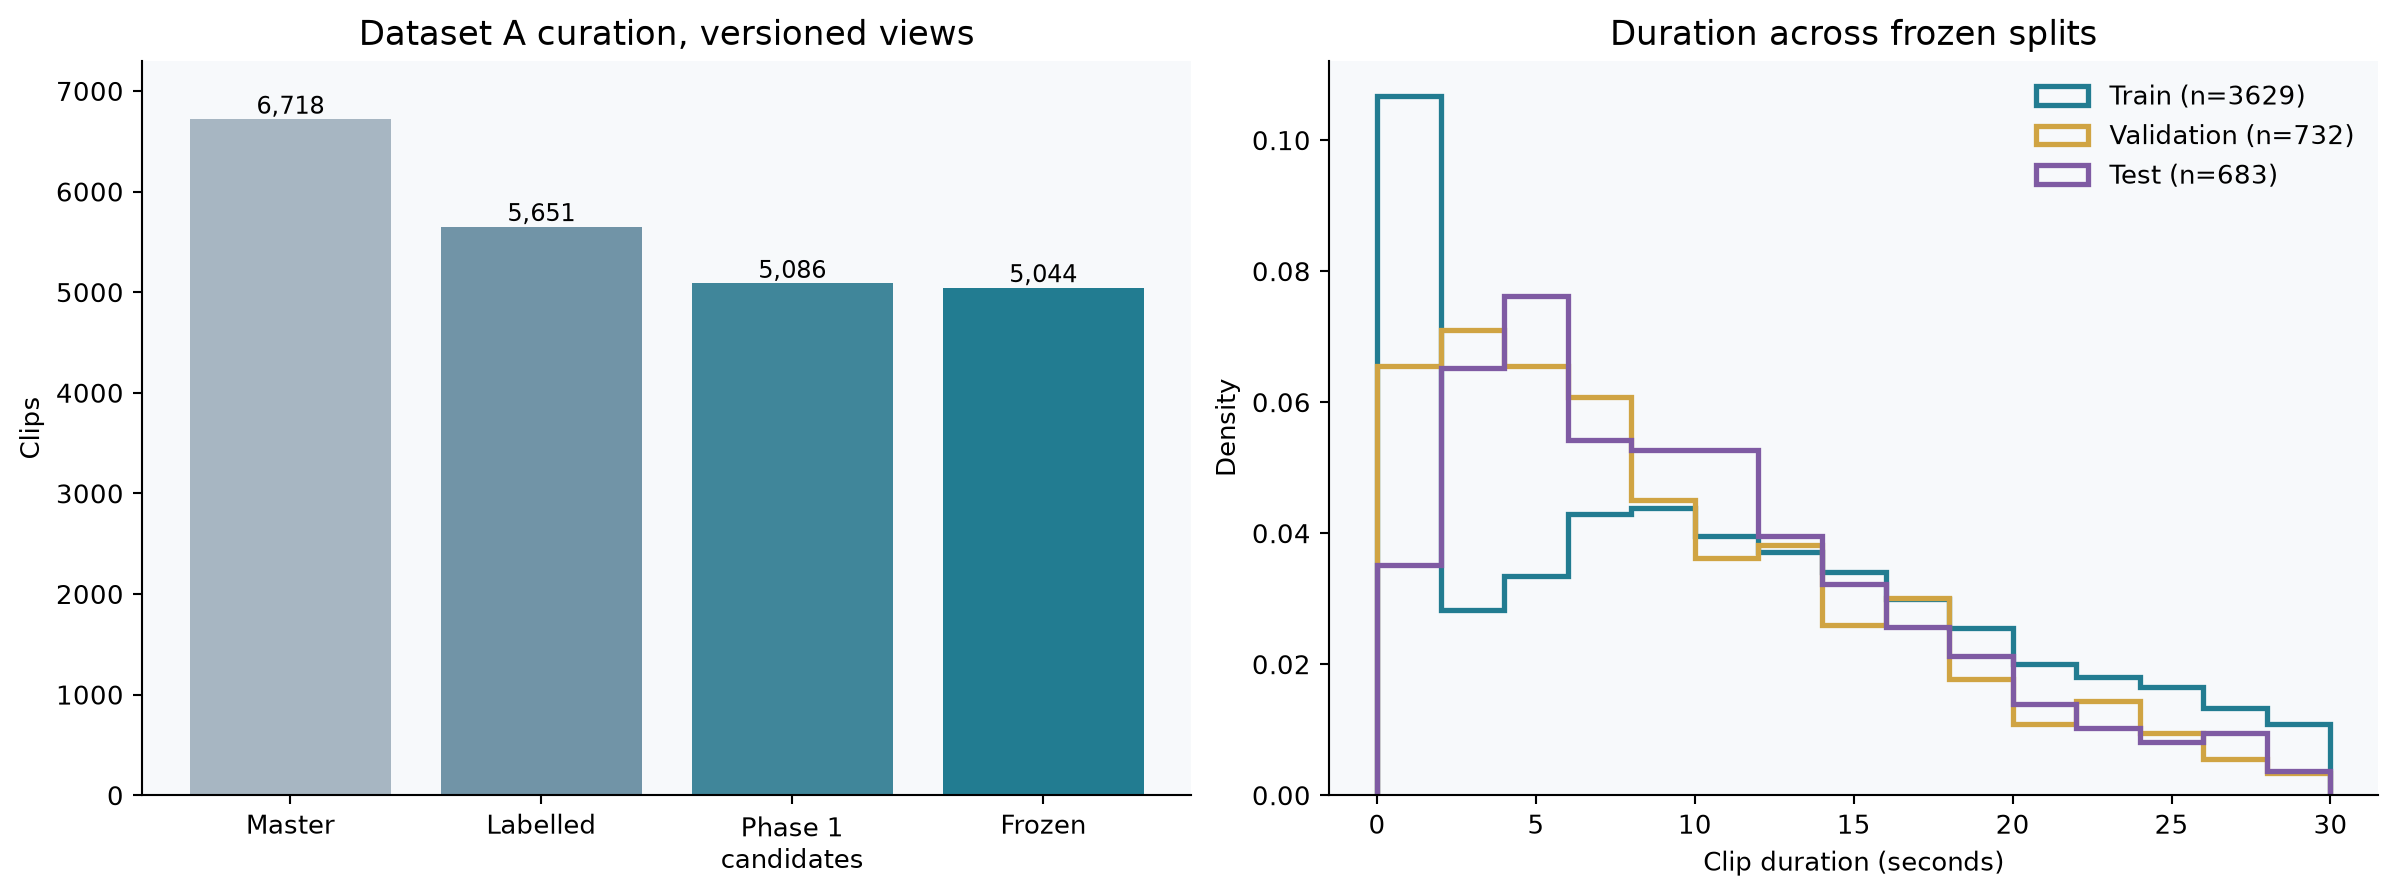

Displaying EDA figures: 2/9 (22%)


### 02 Split Metadata Balance

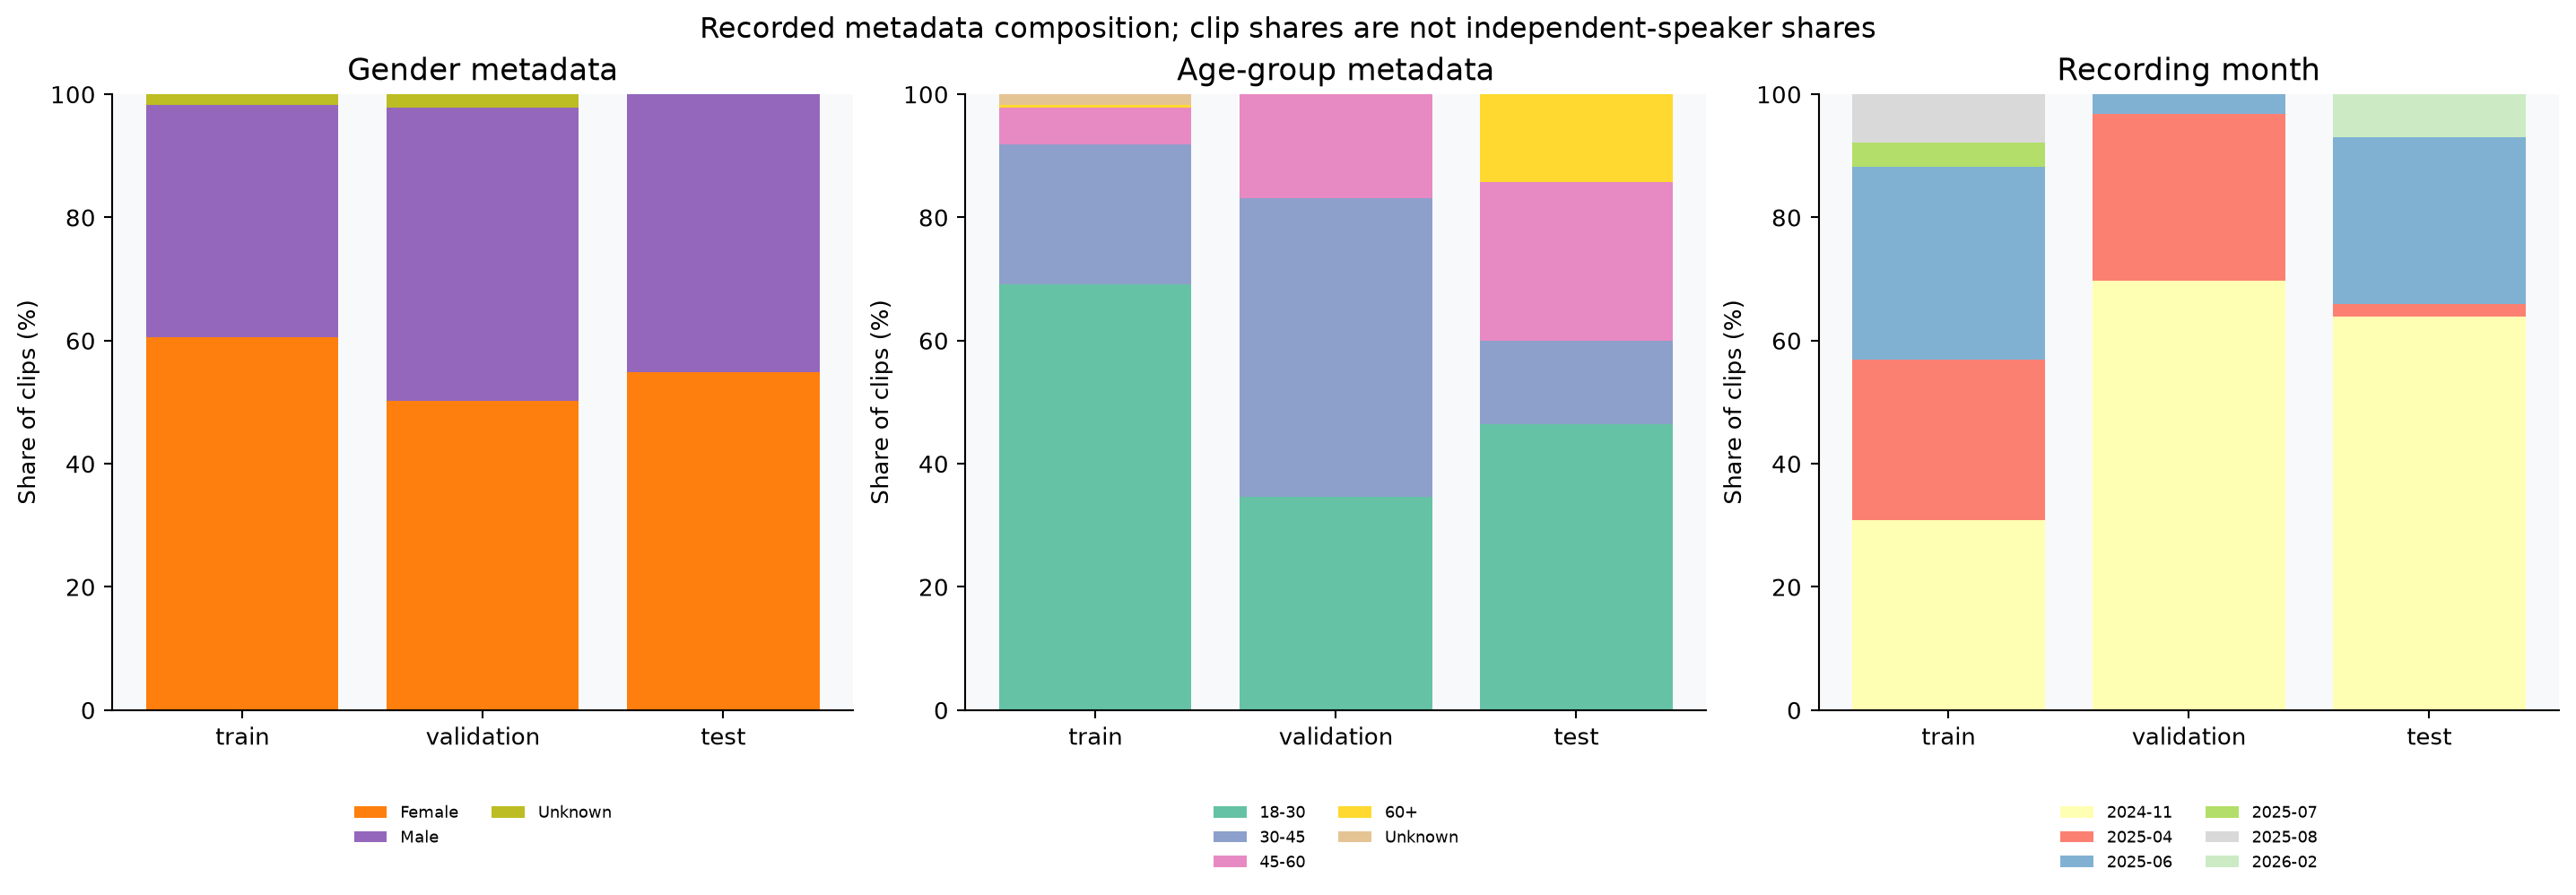

Displaying EDA figures: 3/9 (33%)


### 03 Test Overall Errors And Generation

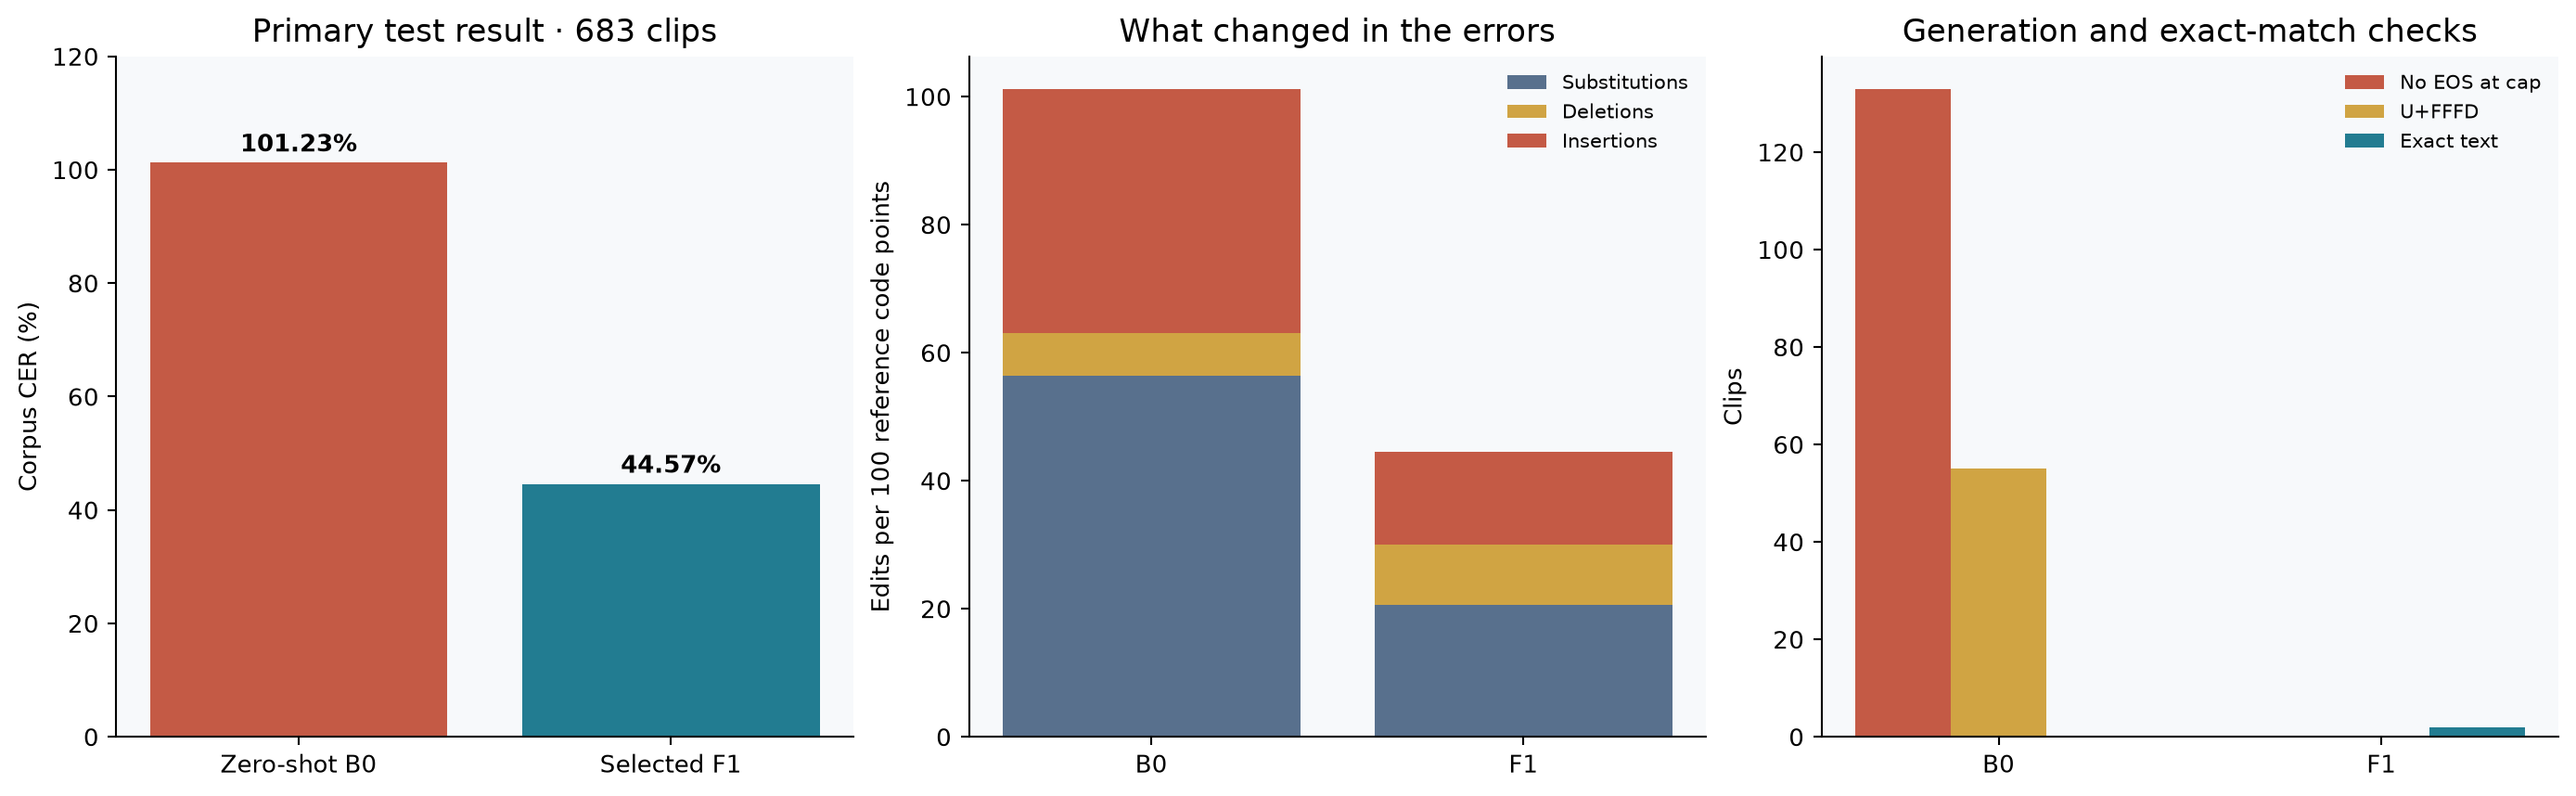

Displaying EDA figures: 4/9 (44%)


### 04 Cer Vs Duration

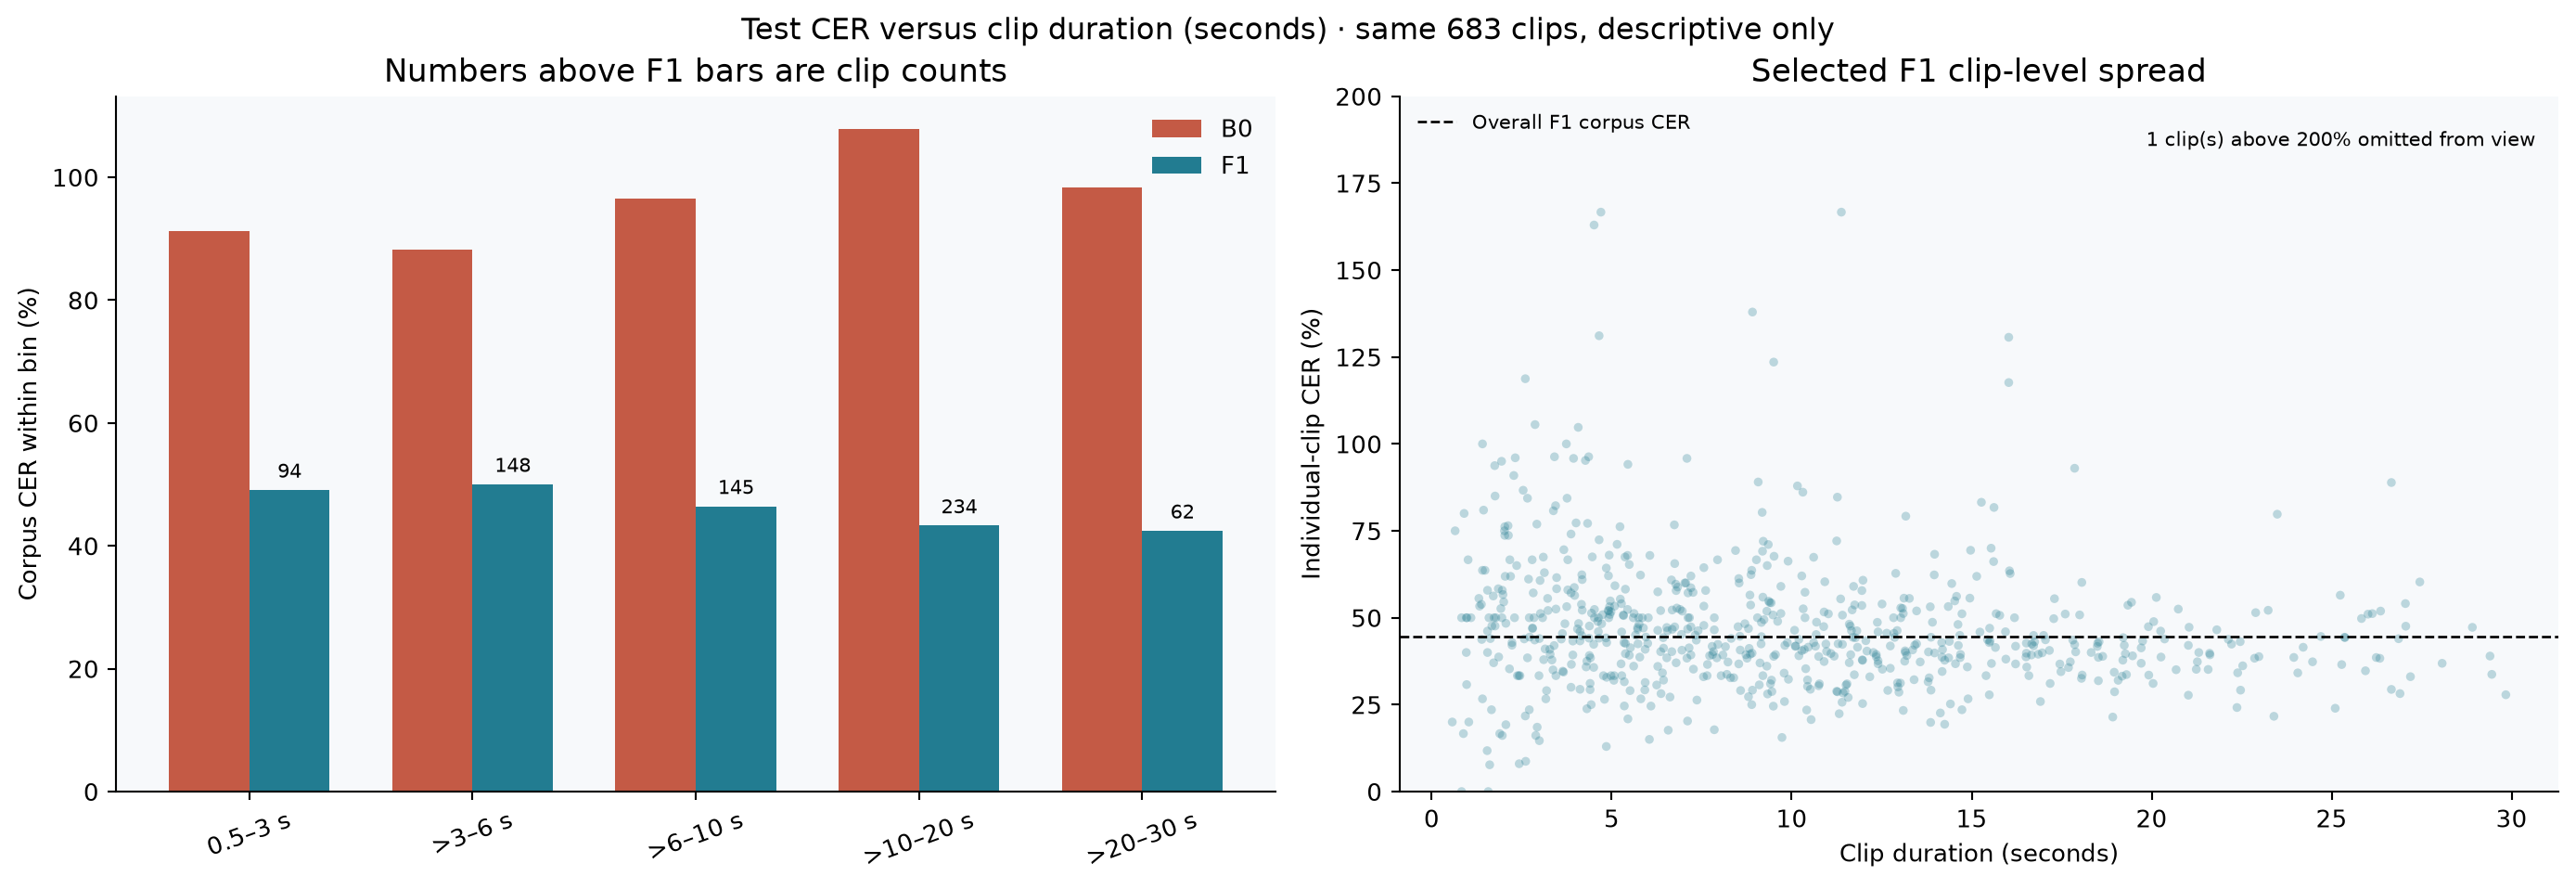

Displaying EDA figures: 5/9 (56%)


### 05 Cer Vs Reference Length

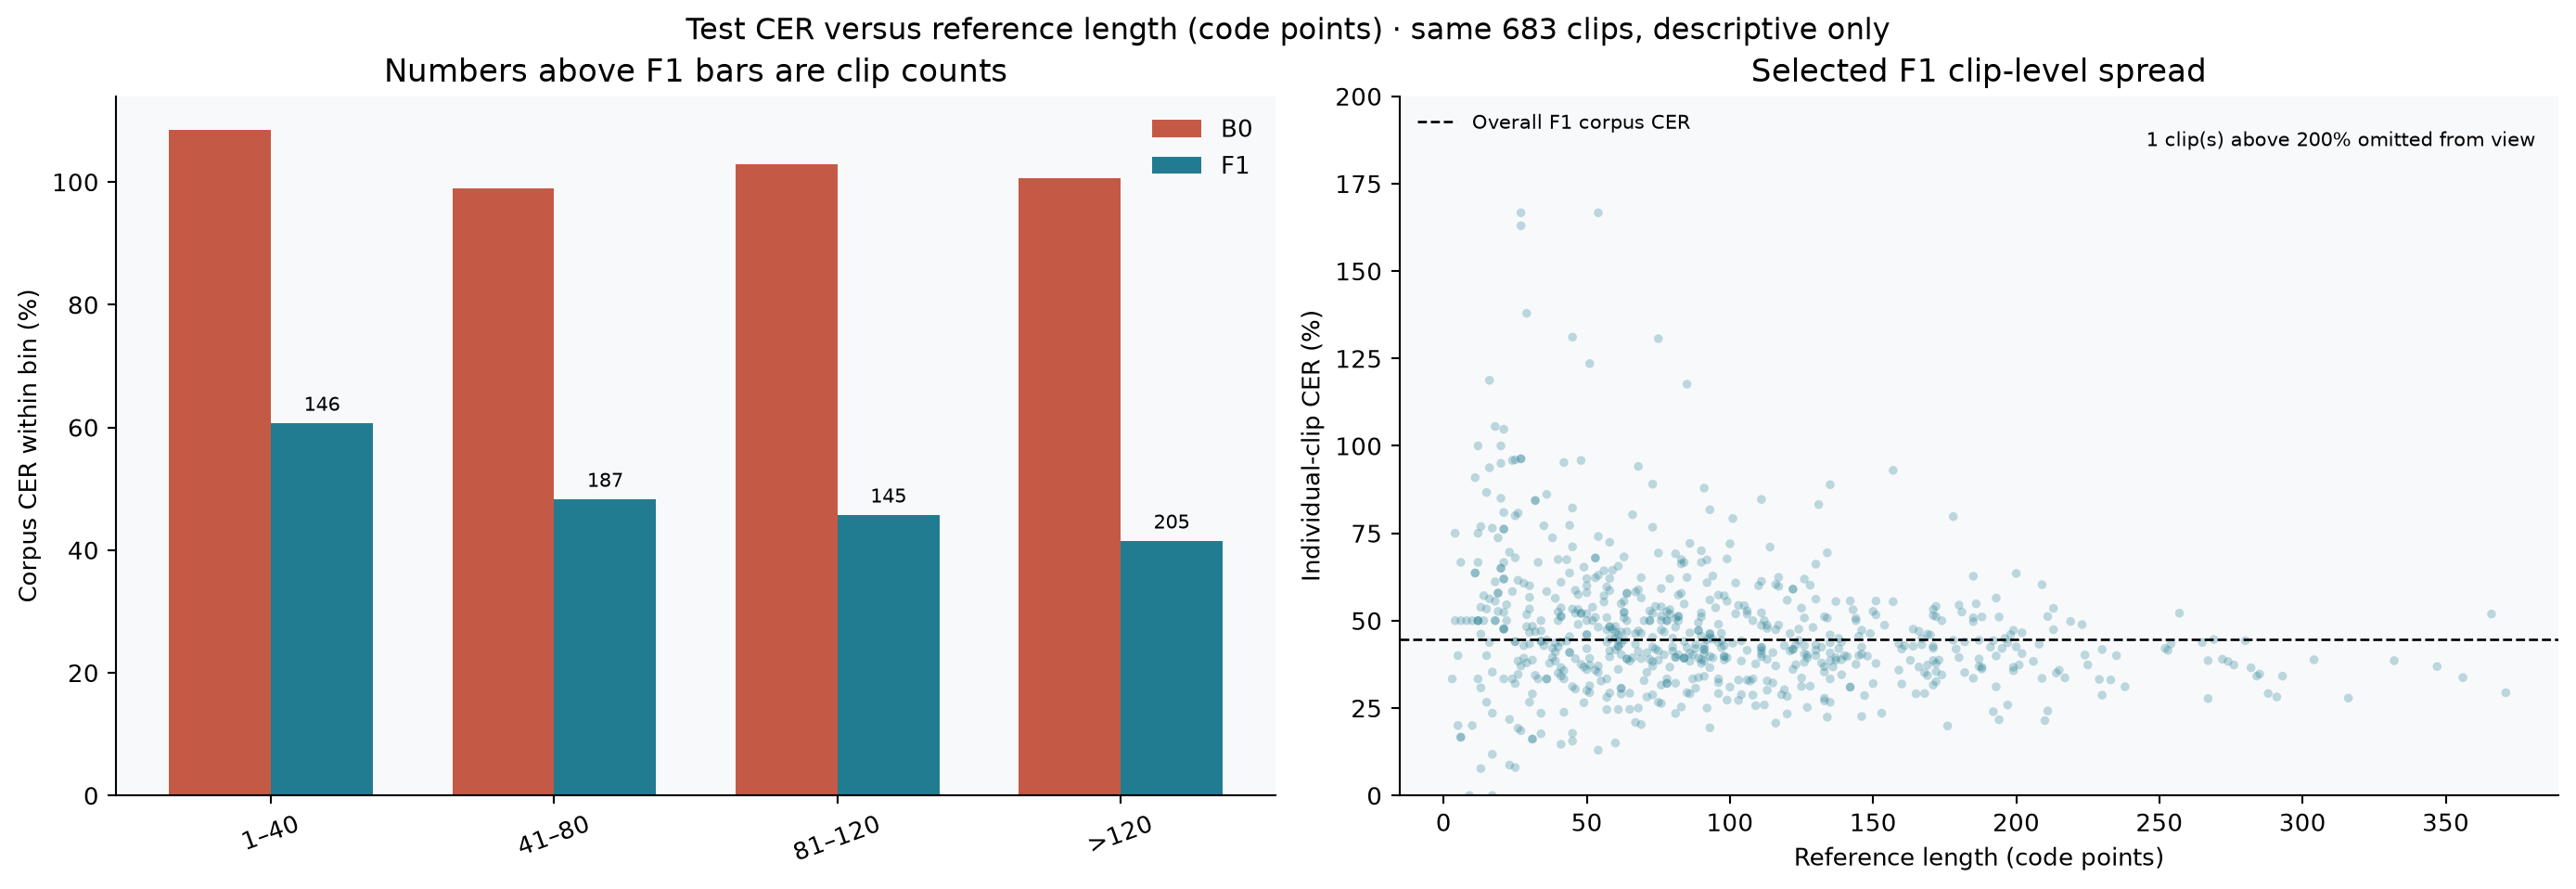

Displaying EDA figures: 6/9 (67%)


### 06A Cer By Gender

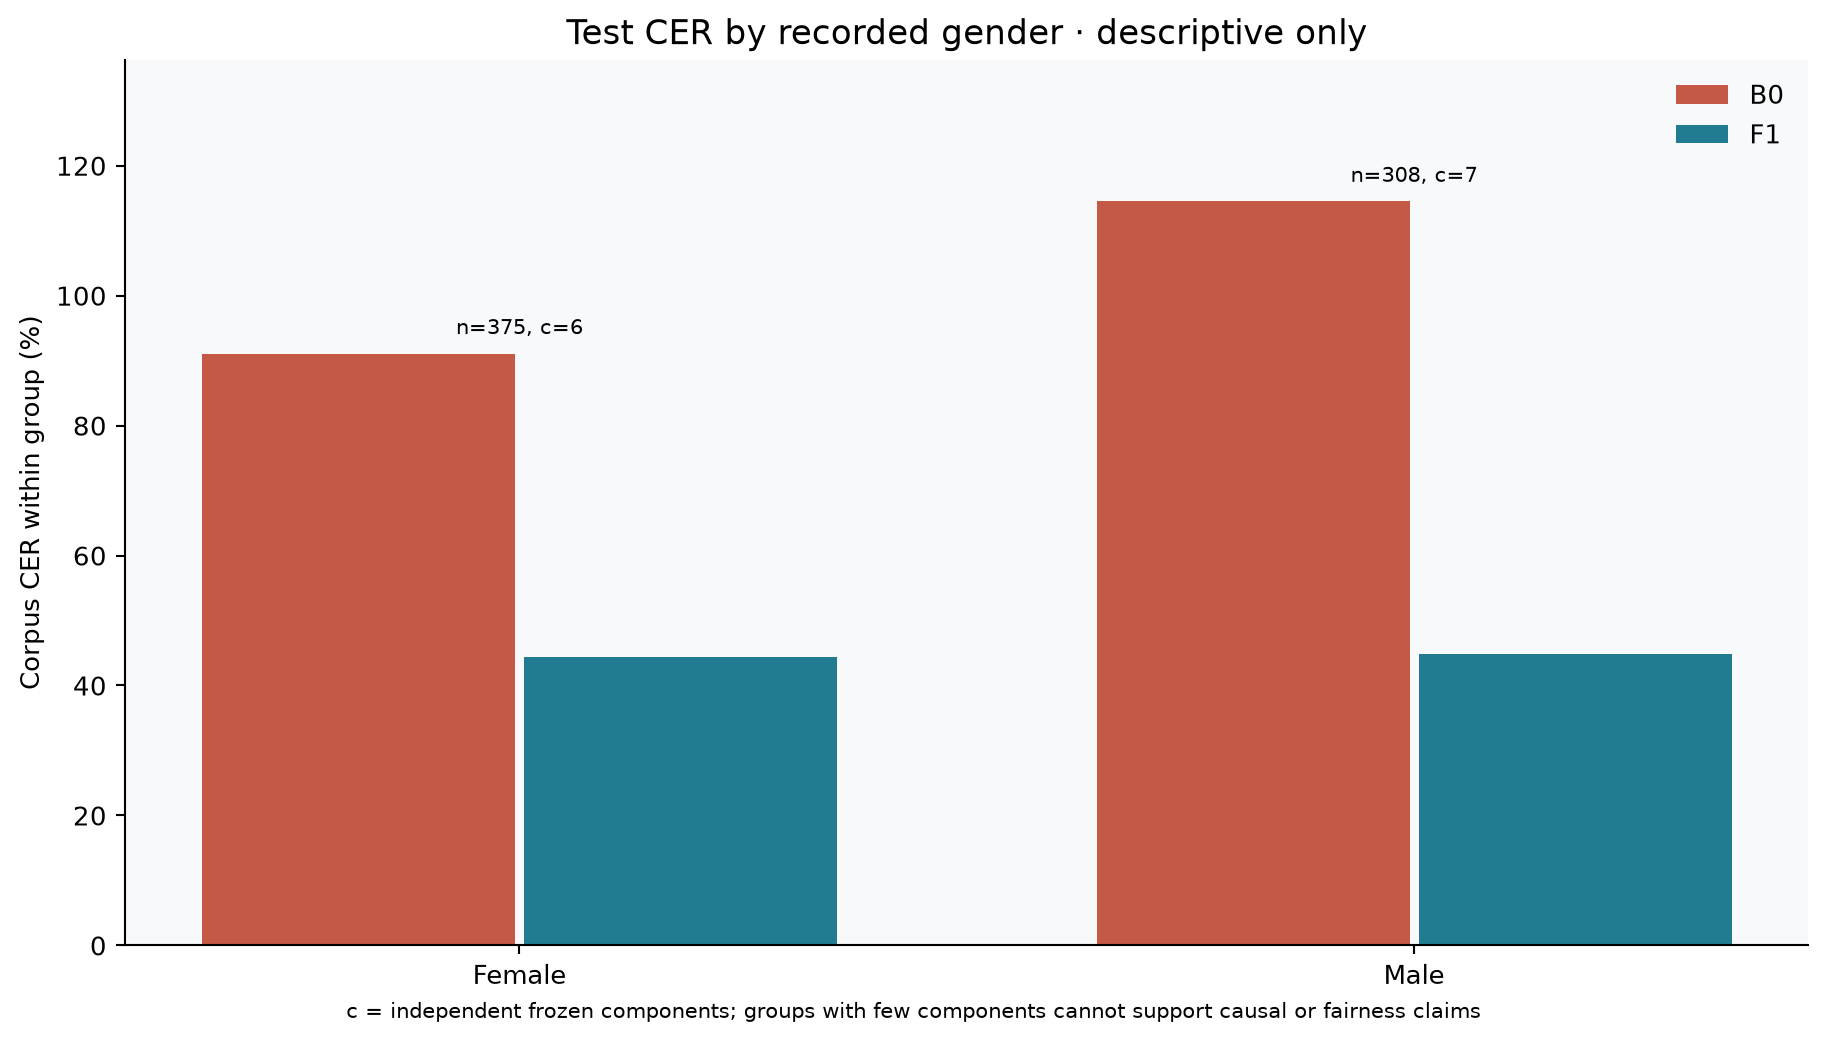

Displaying EDA figures: 7/9 (78%)


### 06B Cer By Age

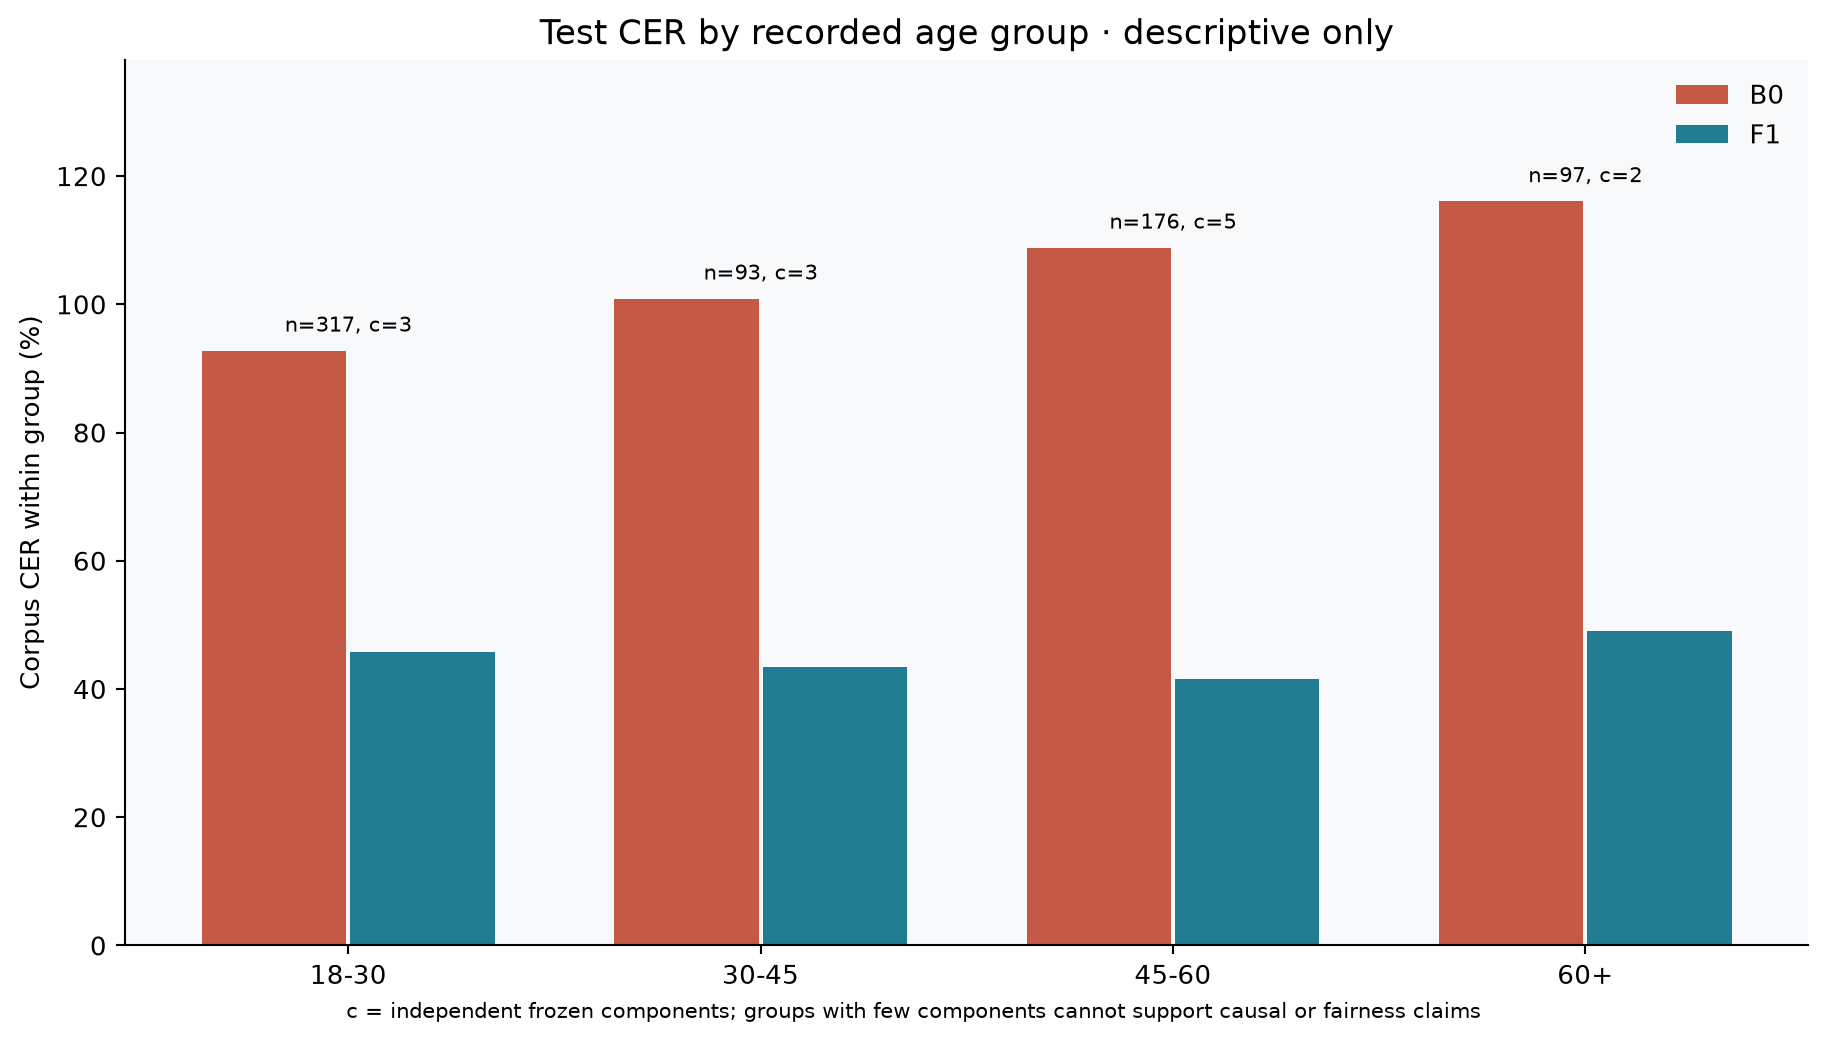

Displaying EDA figures: 8/9 (89%)


### 07 Clip Cer Distribution And Pairing

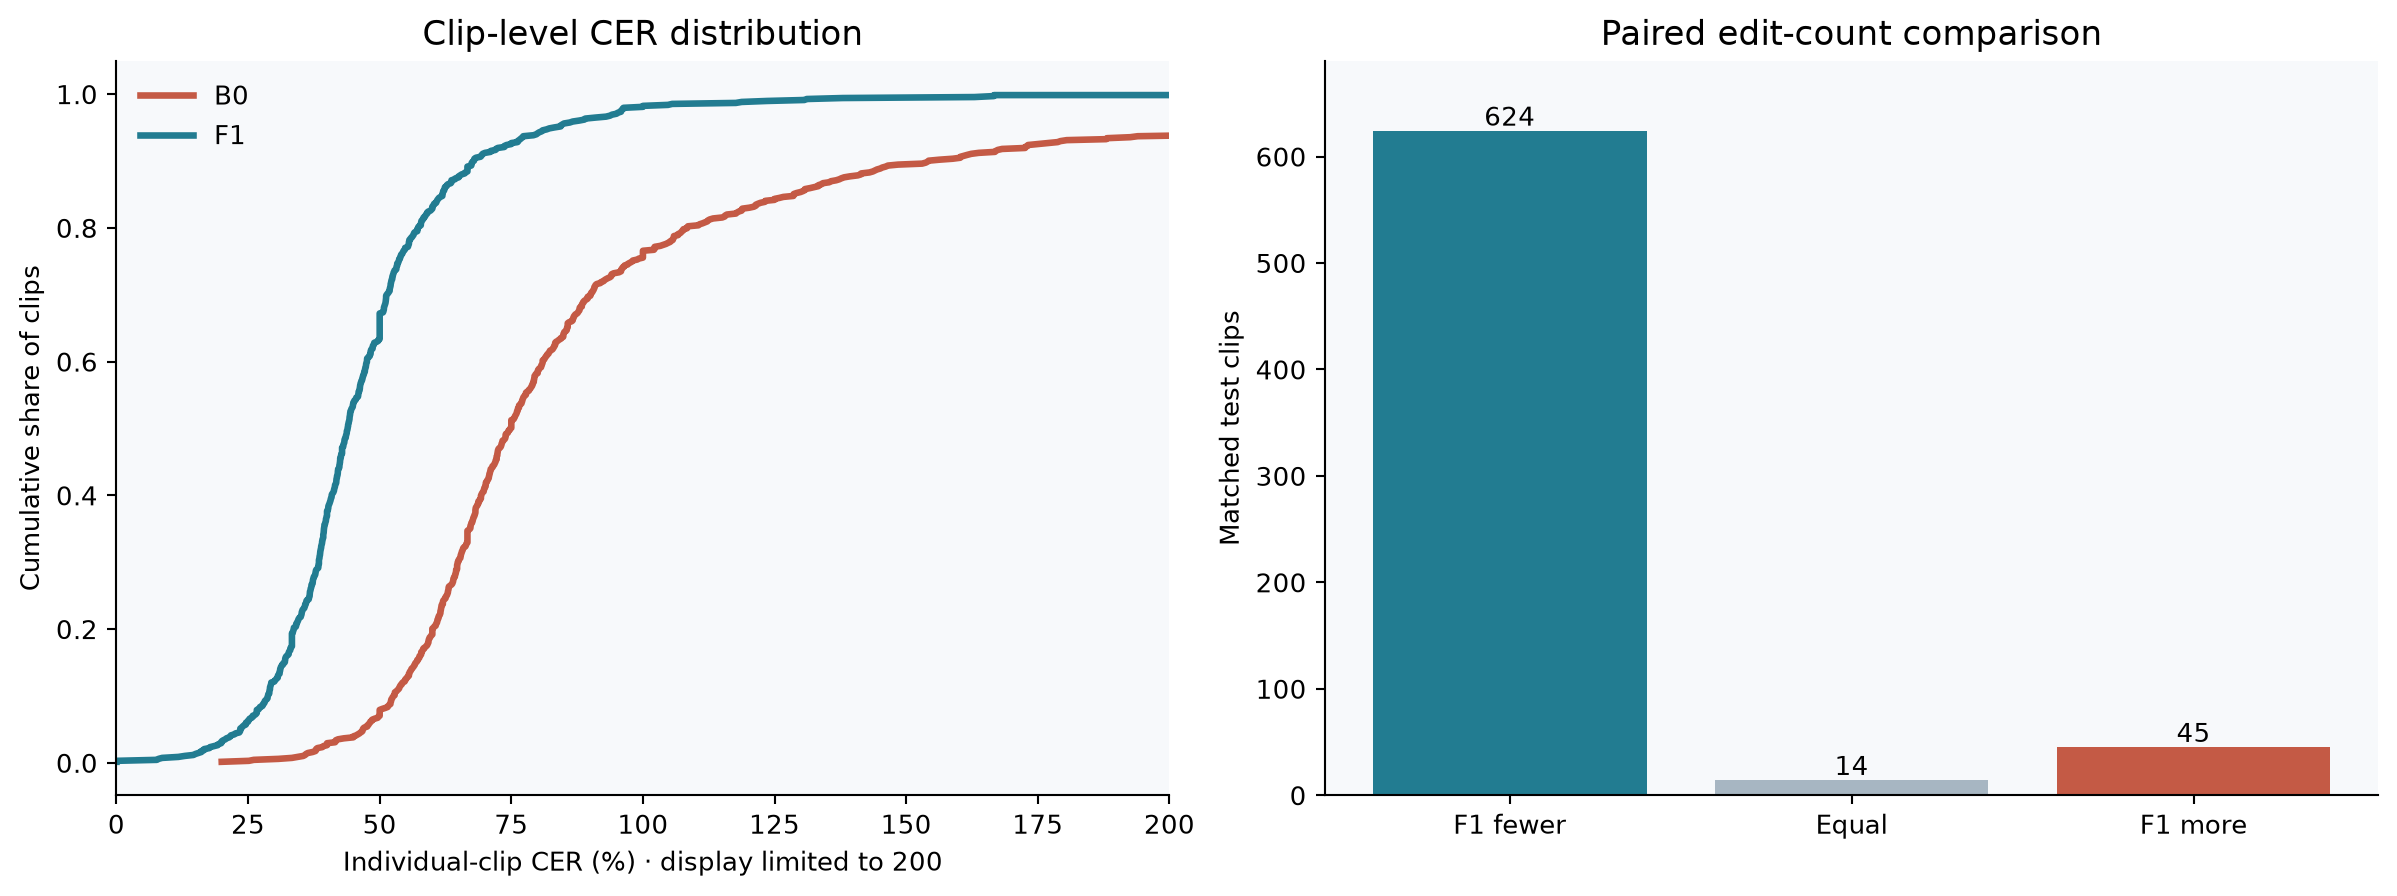

Displaying EDA figures: 9/9 (100%)


### 08 Month And Domain Diagnostics

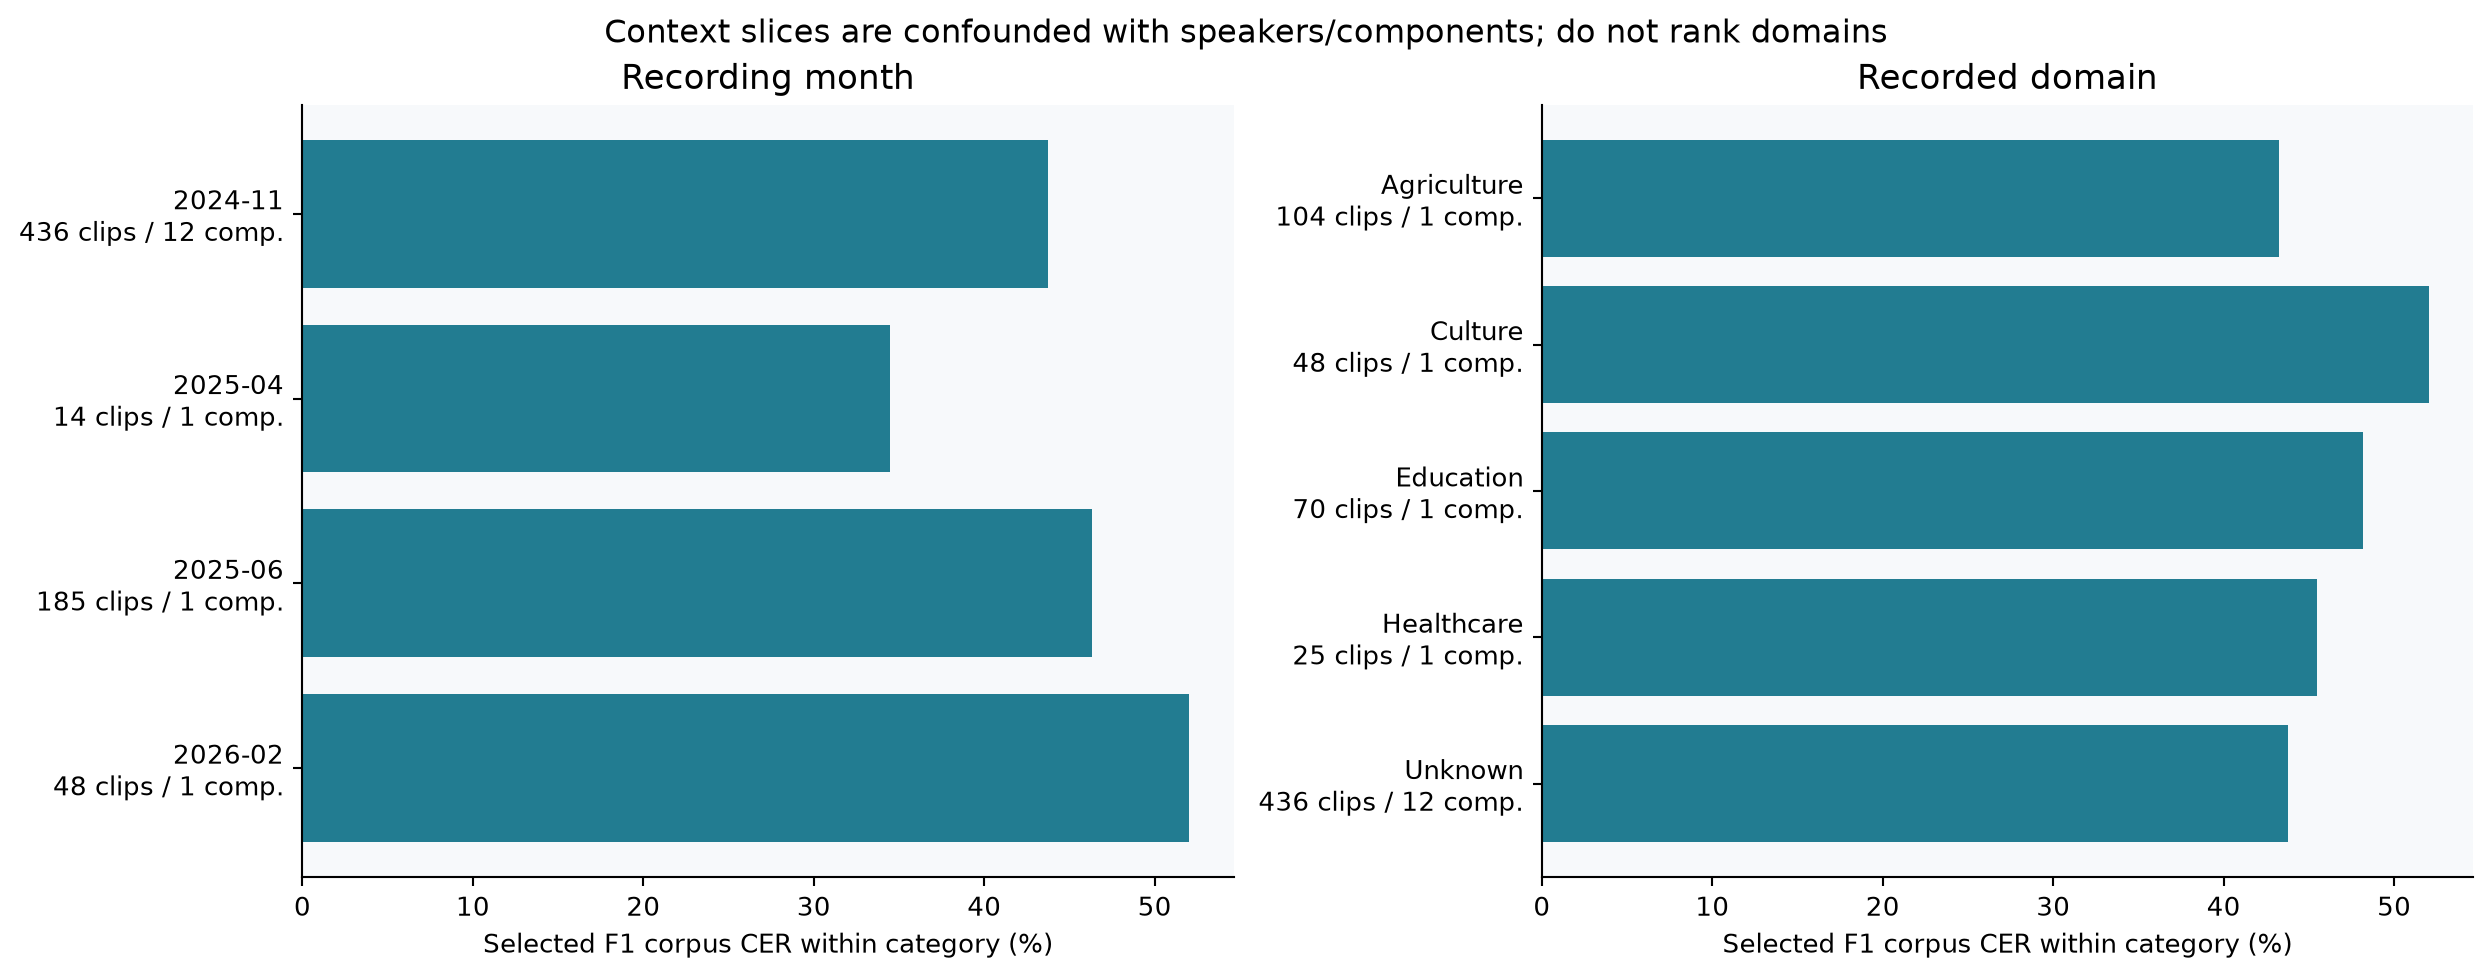

All figures displayed. No private rows were exported.


In [10]:
# Display the aggregate plots with clear headings, in report order.
from IPython.display import Image, Markdown, display
for path in tqdm(sorted(plots.glob("*.png")), desc="Displaying EDA figures", unit="figure"):
    display(Markdown(f"### {path.stem.replace('_', ' ').title()}"))
    display(Image(filename=str(path), width=900))
print("All figures displayed. No private rows were exported.")
